<a href="https://colab.research.google.com/github/Birku15/birku15.github.io/blob/main/Hybrid_AI_Education_Ethiopia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid AI for Predicting Educational Attainment in Ethiopia

This notebook uses `AI@Education Ethiopia.csv` to predict **Education Status** from the other available variables. It combines several machine-learning learners in a **stacking ensemble** and includes a neural-network learner (MLP) as one of the base models.

**Important:** This dataset contains demographic and socioeconomic variables, not direct measures of school performance. Interpret the target as the dataset's recorded `Education Status`, not as a causal explanation of educational attainment. Check that the dataset's sampling and labels are suitable for your research question before reporting results.

## Cell 1 — Install/import libraries
Run the install command only if a library is missing.

In [ ]:
# If needed, uncomment and run:
# %pip install -U pandas numpy matplotlib seaborn scikit-learn joblib

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
    RandomForestRegressor
)
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score, roc_auc_score
)
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
print("Python:", sys.version.split()[0])
print("Ready.")


Python: 3.13.18
Ready.


## Cell 2 — Load the CSV file
Put the CSV in the same folder as this notebook, or change `DATA_PATH` to its full path.

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

DATA_PATH = next(iter(uploaded))

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Saving AI@Education Ethiopia.csv to AI@Education Ethiopia.csv
Dataset shape: (20870, 9)


,Age,Region,Place of residence,Religion,Sex,Wealth index,Marital status,employment Status,Education Status
0,30,sidama,rural,protestant,male,middle,married,no,primary
1,20,sidama,rural,protestant,male,middle,never in union,no,secondary
2,24,sidama,rural,protestant,male,poorer,married,yes,primary
3,28,sidama,rural,protestant,male,poorest,married,no,primary
4,31,sidama,rural,protestant,male,poorer,married,no,primary



Column names:
['Age', 'Region ', 'Place of residence ', 'Religion', 'Sex', 'Wealth index ', 'Marital status', ' employment Status', 'Education Status']


## Cell 3 — Clean column names and inspect the data
This removes accidental leading/trailing spaces in column names, including the space before `employment Status`.

In [ ]:
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\\nMissing values:")
display(df.isna().sum().rename("missing_count").to_frame())
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nUnique values per column:")
display(df.nunique().rename("unique_count").to_frame())


Shape: (20870, 9)
\nData types:


,dtype
Age,int64
Region,object
Place of residence,object
Religion,object
Sex,object
Wealth index,object
Marital status,object
employment Status,object
Education Status,object


\nMissing values:


,missing_count
Age,0
Region,0
Place of residence,0
Religion,0
Sex,0
Wealth index,0
Marital status,0
employment Status,0
Education Status,0


\nDuplicate rows: 6369
\nUnique values per column:


,unique_count
Age,35
Region,14
Place of residence,2
Religion,6
Sex,2
Wealth index,5
Marital status,6
employment Status,2
Education Status,4


In [ ]:
missing_analysis = pd.DataFrame({
    'Total Records': len(df),
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100,
    'Available Values': df.notnull().sum(),
    'Available Percentage': (df.notnull().sum() / len(df)) * 100
})

print(missing_analysis.round(2))

                    Total Records  Missing Values  Missing Percentage  \
Age                         20870               0                 0.0   
Region                      20870               0                 0.0   
Place of residence          20870               0                 0.0   
Religion                    20870               0                 0.0   
Sex                         20870               0                 0.0   
Wealth index                20870               0                 0.0   
Marital status              20870               0                 0.0   
employment Status           20870               0                 0.0   
Education Status            20870               0                 0.0   

                    Available Values  Available Percentage  
Age                            20870                 100.0  
Region                         20870                 100.0  
Place of residence             20870                 100.0  
Religion                 

In [ ]:
# Count duplicate rows
total_duplicates = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", total_duplicates)
print("Unique records:", len(df) - total_duplicates)
# Display all duplicate rows, including the first occurrence
duplicates = df[df.duplicated(keep=False)]

display(duplicates)

Total records: 20870
Duplicate records: 6369
Unique records: 14501


,Age,Region,Place of residence,Religion,Sex,Wealth index,Marital status,employment Status,Education Status
0,30,sidama,rural,protestant,male,middle,married,no,primary
1,20,sidama,rural,protestant,male,middle,never in union,no,secondary
3,28,sidama,rural,protestant,male,poorest,married,no,primary
4,31,sidama,rural,protestant,male,poorer,married,no,primary
5,17,sidama,rural,protestant,male,poorer,never in union,no,primary
...,...,...,...,...,...,...,...,...,...
20865,38,tigray,rural,orthodox,male,middle,married,no,no education
20866,17,tigray,rural,orthodox,male,middle,never in union,no,primary
20867,17,tigray,rural,orthodox,male,poorer,never in union,no,primary
20868,49,tigray,rural,orthodox,male,poorest,married,no,no education


## Cell 4 — Basic cleaning
The code removes exact duplicate rows, standardizes text spacing, and converts `Age` to numeric. It does not invent missing values.

In [ ]:
df = df.copy()

print("Original records:", df.shape[0])
import pandas as pd
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns
# Numerical variables: Mean imputation
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

# Categorical variables: Mode imputation
for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Records after imputation:", df.shape[0])

print("Remaining missing values:", df.isnull().sum().sum())
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Records after encoding:", df_encoded.shape[0])
print("Features after encoding:", df_encoded.shape[1])
print("Final dataset dimensions:", df_encoded.shape)
print("Final record count:", len(df_encoded))
print("Missing values:", df_encoded.isnull().sum().sum())

Original records: 20870
Records after imputation: 20870
Remaining missing values: 0
Records after encoding: 20870
Features after encoding: 34
Final dataset dimensions: (20870, 34)
Final record count: 20870
Missing values: 0


## Cell 5 — Explore the target and key variables

Target distribution:


,count
Education Status,
primary,7911
no education,7062
secondary,3753
higher,2144


,percentage
Education Status,
primary,37.91
no education,33.84
secondary,17.98
higher,10.27


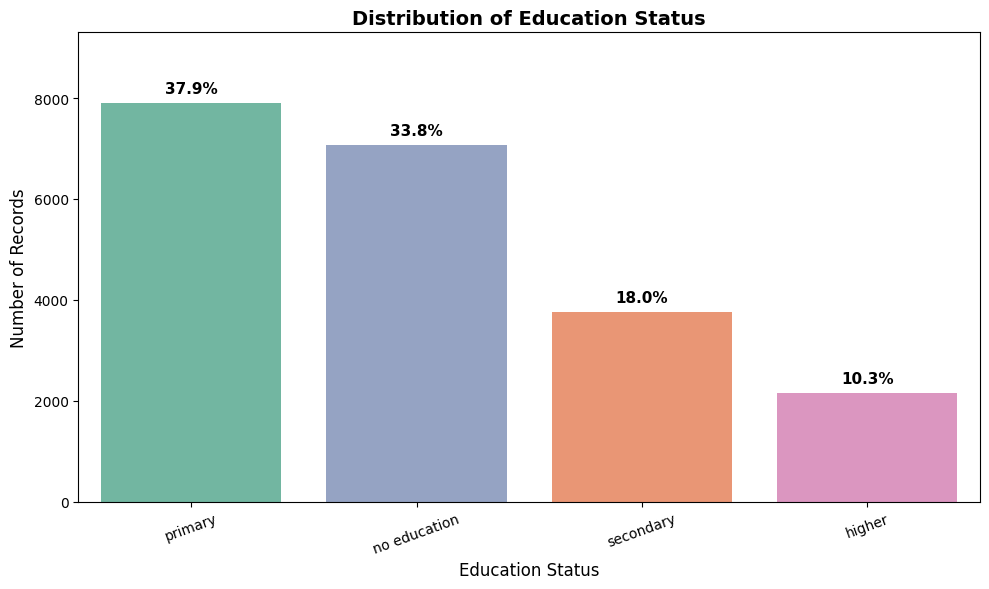

In [ ]:
TARGET = "Education Status"

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

print("Target distribution:")
display(df[TARGET].value_counts(dropna=False).rename("count").to_frame())

display(
    (df[TARGET].value_counts(normalize=True, dropna=False) * 100)
    .round(2).rename("percentage").to_frame()
)

plt.figure(figsize=(10, 6))

order = df[TARGET].value_counts().index

ax = sns.countplot(
    data=df,
    x=TARGET,
    order=order,
    hue=TARGET,
    palette="Set2",
    legend=False
)

total = len(df)

# Add percentage above each bar
for bar in ax.patches:
    height = bar.get_height()
    percentage = (height / total) * 100

    ax.annotate(
        f'{percentage:.1f}%',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.title("Distribution of Education Status", fontsize=14, fontweight="bold")
plt.xlabel("Education Status", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=20)
plt.ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate missing percentage
missing = df.isnull().mean() * 100

# Keep variables with missing values
missing = missing[missing > 0].sort_values(ascending=False)

# Plot only if missing values exist
if not missing.empty:
    plt.figure(figsize=(12, 6))
    missing.plot(kind='bar', edgecolor='black')

    plt.title('Missing Data Percentage by Variable')
    plt.xlabel('Variables')
    plt.ylabel('Missing Percentage (%)')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected in the dataset.")
    print(df.isnull().sum().sort_values(ascending=False).head(20))

No missing values detected in the dataset.
Age                   0
Region                0
Place of residence    0
Religion              0
Sex                   0
Wealth index          0
Marital status        0
employment Status     0
Education Status      0
dtype: int64


In [ ]:
# Separate numerical and categorical columns
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

print("Numerical variables:", len(numeric_cols))
print("Categorical variables:", len(categorical_cols))

Numerical variables: 1
Categorical variables: 8


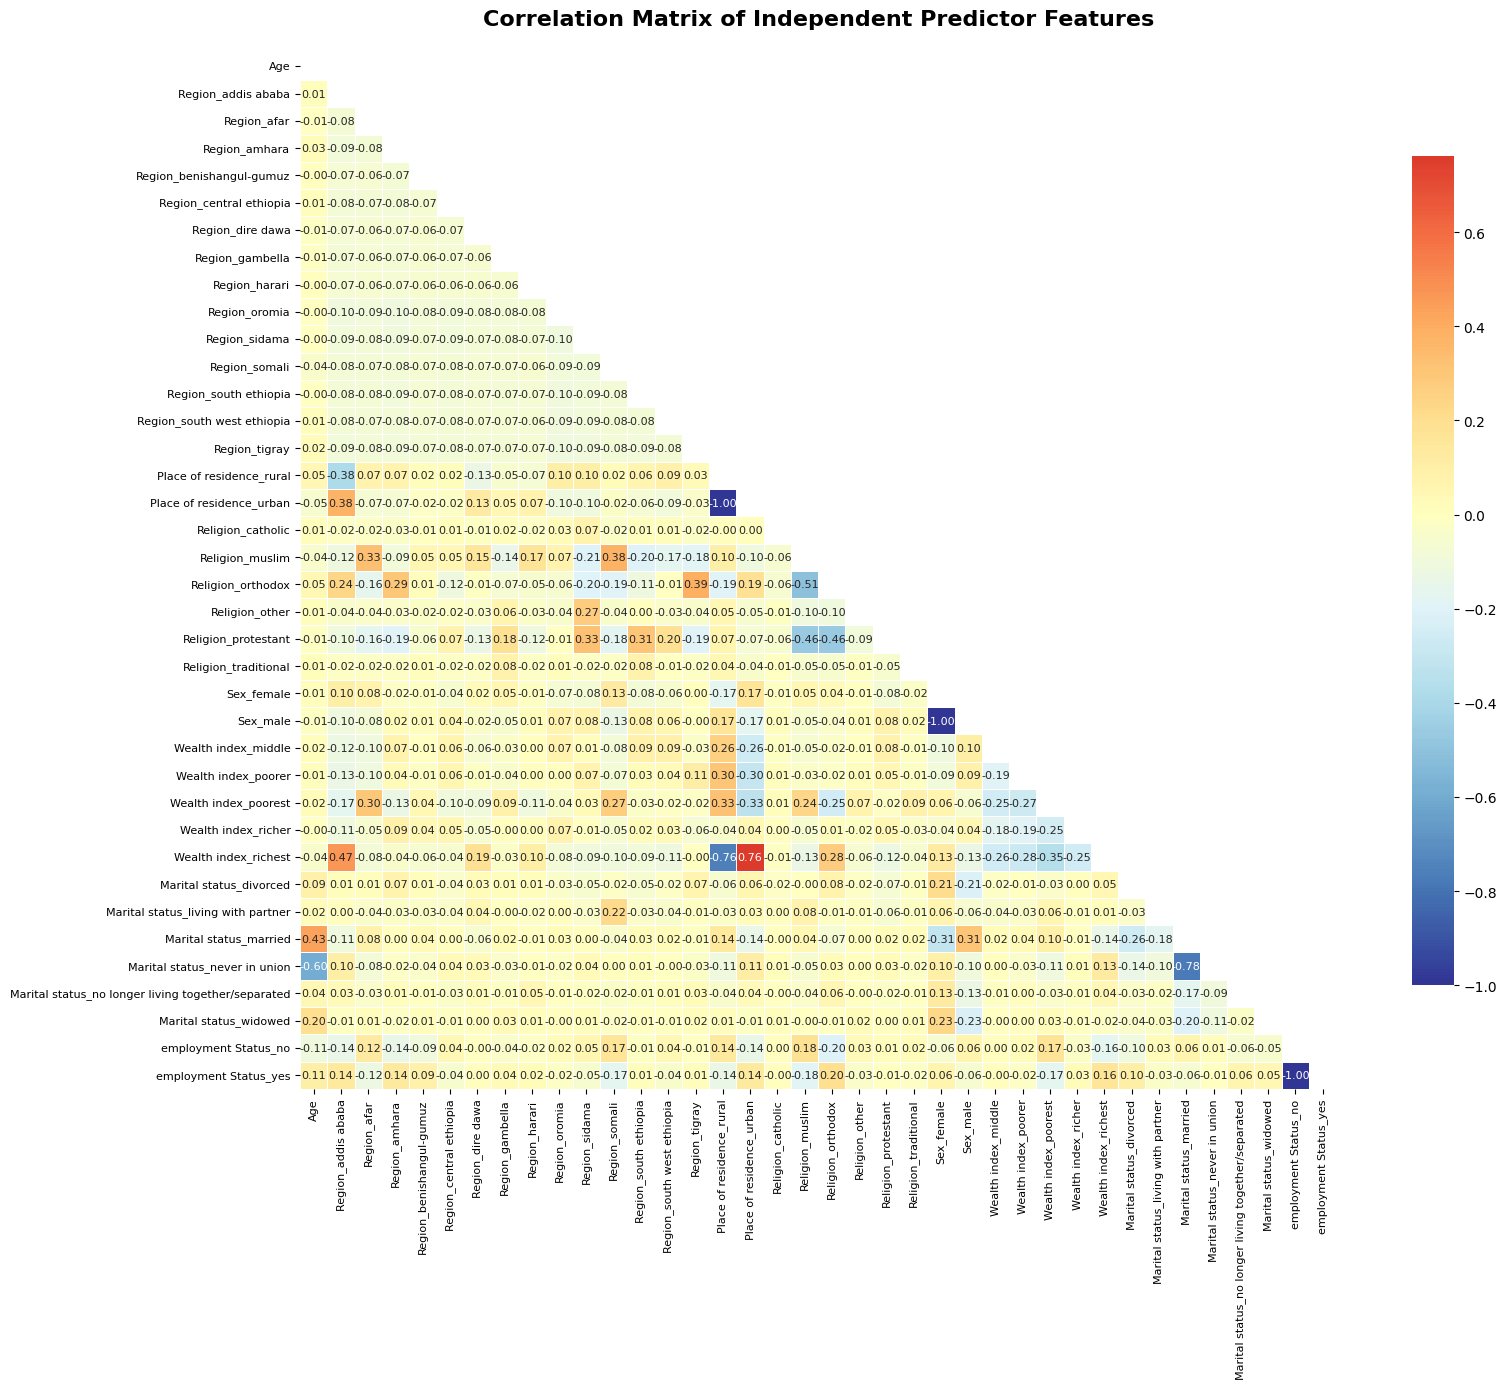

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select independent predictor features
features = [
    "Age",
    "Region",
    "Place of residence",
    "Religion",
    "Sex",
    "Wealth index",
    "Marital status",
    "employment Status"
]

# 2. Validate columns
missing = [col for col in features if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# 3. Create predictor dataset
X_corr = df[features].copy()

# 4. Convert Age to numeric
X_corr["Age"] = pd.to_numeric(
    X_corr["Age"], errors="coerce"
)

# 5. Encode categorical predictors
X_encoded = pd.get_dummies(
    X_corr,
    columns=[col for col in features if col != "Age"],
    dtype=int
)

# 6. Calculate Pearson correlation
corr_matrix = X_encoded.corr(method="pearson")

# 7. Visualize correlation matrix
plt.figure(figsize=(18, 14))

mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool)
)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8}
)

plt.title(
    "Correlation Matrix of Independent Predictor Features",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (df[numeric_cols] < lower_bound) |
    (df[numeric_cols] > upper_bound)
).sum()

print("Potential outliers:")
print(outliers.sort_values(ascending=False))

Potential outliers:
Age    0
dtype: int64


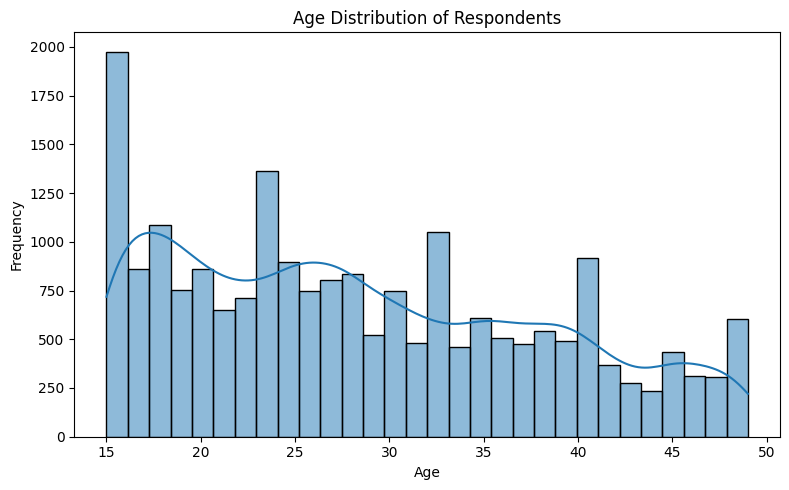

In [ ]:
# ==========================================
# STEP 6.2: AGE DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Respondents")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

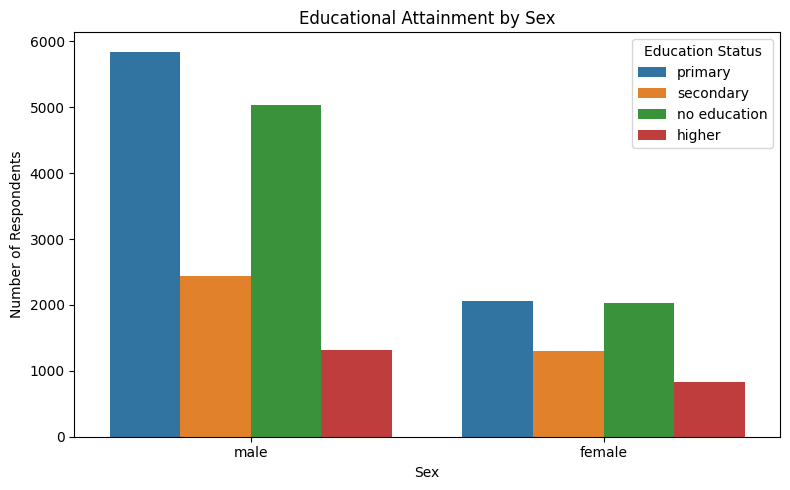

In [ ]:
# ==========================================
# STEP 6.3: EDUCATION BY SEX
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Education Status"
)

plt.title("Educational Attainment by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

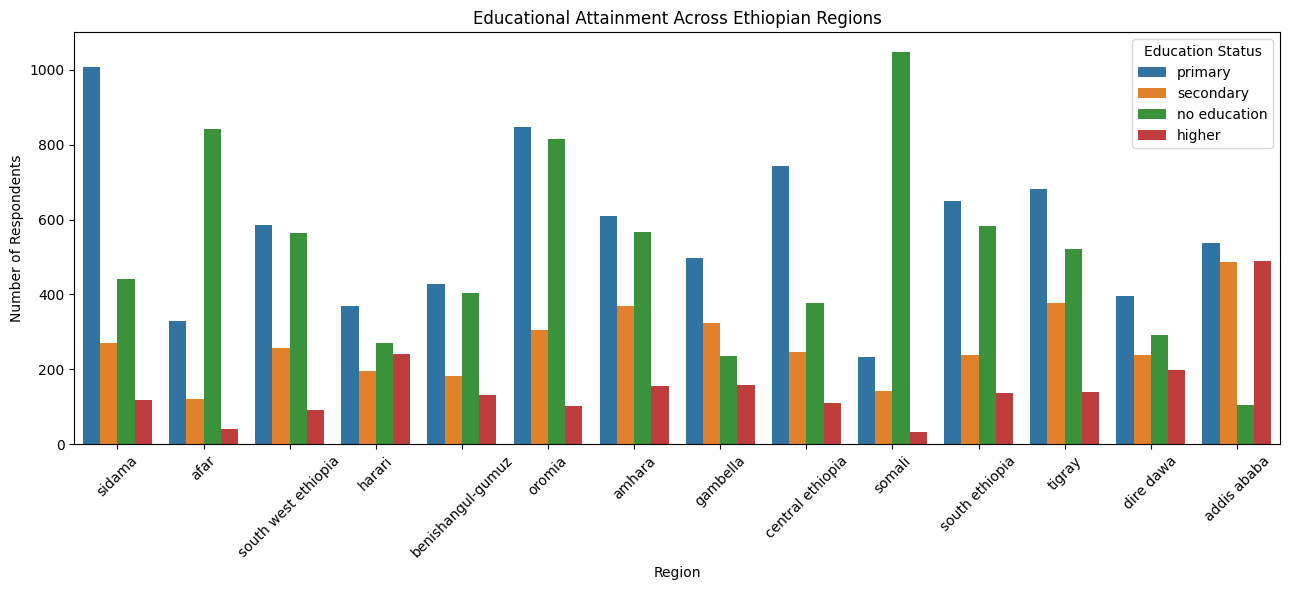

In [ ]:
# ==========================================
# STEP 6.4: EDUCATION BY REGION
# ==========================================

plt.figure(figsize=(13, 6))

sns.countplot(
    data=df,
    x="Region",
    hue="Education Status"
)

plt.title("Educational Attainment Across Ethiopian Regions")
plt.xlabel("Region")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Cell 6 — Define features and target
`Education Status` is the prediction target. It is excluded from the input features to prevent target leakage.

In [ ]:
# ==========================================
# STEP 7: FEATURE AND TARGET SELECTION
# ==========================================

X = df.drop(columns=["Education Status"])

y = df["Education Status"]

print("Independent variables:")
print(X.columns.tolist())

print("\nDependent variable:")
print(y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget categories:")
print(y.unique())

Independent variables:
['Age', 'Region', 'Place of residence', 'Religion', 'Sex', 'Wealth index', 'Marital status', 'employment Status']

Dependent variable:
Education Status

X shape: (20870, 8)
y shape: (20870,)

Target categories:
['primary' 'secondary' 'no education' 'higher']


In [ ]:
# ==========================================
# STEP 8: TARGET LABEL ENCODING
# ==========================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original categories:")
print(label_encoder.classes_)

print("\nEncoded categories:")

for original, encoded in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(original, "=", encoded)

Original categories:
['higher' 'no education' 'primary' 'secondary']

Encoded categories:
higher = 0
no education = 1
primary = 2
secondary = 3


In [ ]:
# ==========================================
# STEP 9: FEATURE IDENTIFICATION
# ==========================================

numerical_features = ["Age"]

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age']

Categorical features:
['Region', 'Place of residence', 'Religion', 'Sex', 'Wealth index', 'Marital status', 'employment Status']


## Cell 7 — Split into training and testing sets
Use a stratified split so each target class is represented proportionally in both sets.

In [ ]:
# ==========================================
# STEP 10: TRAIN-TEST SPLITTING
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts())

Training records: 14609
Testing records: 6261

Training features: (14609, 8)
Testing features: (6261, 8)

Training target distribution:
2    5538
1    4943
3    2627
0    1501
Name: count, dtype: int64

Testing target distribution:
2    2373
1    2119
3    1126
0     643
Name: count, dtype: int64


In [ ]:
# ==========================================
# STEP 10: 70:30 SPLIT + SMOTENC + TOMEK
# ==========================================

import pandas as pd
import numpy as np

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import TomekLinks
from imblearn.combine import SMOTETomek

# ==========================================
# 10.1: TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nBefore balancing:")
print(Counter(y_train))

print("\nOriginal testing distribution:")
print(Counter(y_test))


# ==========================================
# 10.2: IDENTIFY CATEGORICAL FEATURES
# ==========================================

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = [
    col for col in X_train.columns
    if col not in categorical_columns
]

# Preserve original column order
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_columns
]

print("\nCategorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)


# ==========================================
# 10.3: ENCODE CATEGORICAL FEATURES
# ==========================================

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

X_train_encoded[categorical_columns] = encoder.fit_transform(
    X_train[categorical_columns].astype(str)
)

X_test_encoded[categorical_columns] = encoder.transform(
    X_test[categorical_columns].astype(str)
)

# ==========================================
# 10.4: APPLY SMOTENC + TOMEK LINKS
# ==========================================

smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy="not majority",
    random_state=42,
    k_neighbors=5
)

smote_tomek = SMOTETomek(
    smote=smote_nc,
    tomek=TomekLinks(sampling_strategy="all"),
    random_state=42
)

X_train_balanced, y_train_balanced = smote_tomek.fit_resample(
    X_train_encoded,
    y_train
)

# ==========================================
# 10.5: RESTORE ORIGINAL CATEGORY VALUES
# ==========================================

X_train_balanced = pd.DataFrame(
    X_train_balanced,
    columns=X_train.columns
)

X_train_balanced[categorical_columns] = encoder.inverse_transform(
    X_train_balanced[categorical_columns].astype(float)
)

# Restore numerical data types
for col in numerical_columns:
    X_train_balanced[col] = pd.to_numeric(
        X_train_balanced[col]
    )

# ==========================================
# 10.6: DISPLAY RESULTS
# ==========================================

print("\nAFTER SMOTENC + TOMEK")
print("-" * 45)

print("Original training:", X_train.shape)
print("Balanced training:", X_train_balanced.shape)

print("\nBefore balancing:")
print(Counter(y_train))

print("\nAfter balancing:")
print(Counter(y_train_balanced))

print("\nTesting data remains unchanged:")
print(X_test.shape)
print(Counter(y_test))

print("\nBalancing completed successfully!")

Training records: 14609
Testing records: 6261

Before balancing:
Counter({np.int64(2): 5538, np.int64(1): 4943, np.int64(3): 2627, np.int64(0): 1501})

Original testing distribution:
Counter({np.int64(2): 2373, np.int64(1): 2119, np.int64(3): 1126, np.int64(0): 643})

Categorical columns: ['Region', 'Place of residence', 'Religion', 'Sex', 'Wealth index', 'Marital status', 'employment Status']
Numerical columns: ['Age']

AFTER SMOTENC + TOMEK
---------------------------------------------
Original training: (14609, 8)
Balanced training: (20898, 8)

Before balancing:
Counter({np.int64(2): 5538, np.int64(1): 4943, np.int64(3): 2627, np.int64(0): 1501})

After balancing:
Counter({np.int64(1): 5323, np.int64(0): 5213, np.int64(2): 5212, np.int64(3): 5150})

Testing data remains unchanged:
(6261, 8)
Counter({np.int64(2): 2373, np.int64(1): 2119, np.int64(3): 1126, np.int64(0): 643})

Balancing completed successfully!


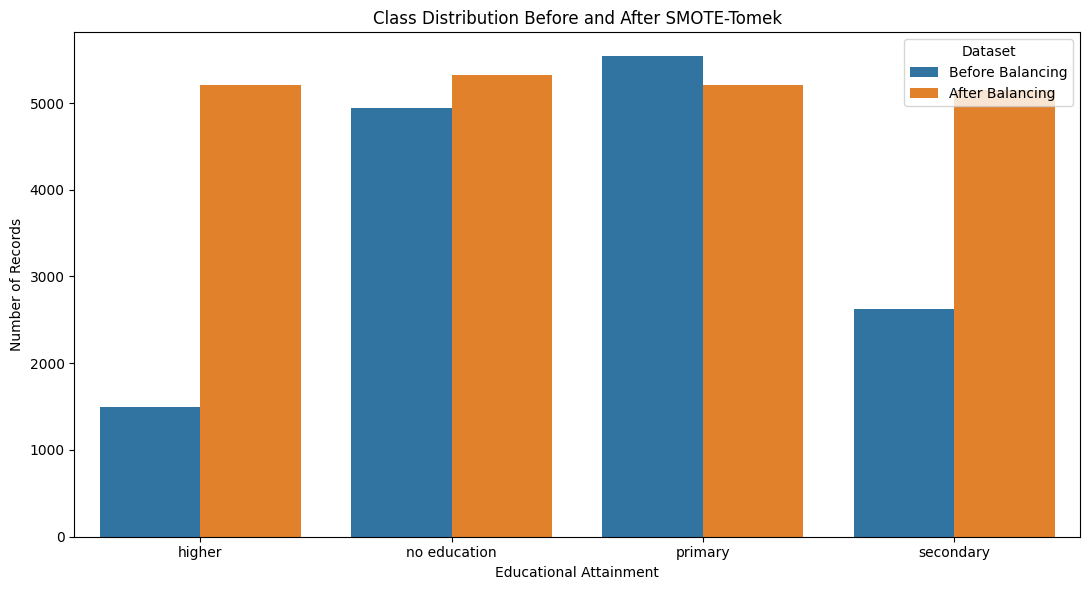

In [ ]:
# ==========================================
# CLASS DISTRIBUTION VISUALIZATION
# ==========================================

before_counts = Counter(y_train)
after_counts = Counter(y_train_balanced)

classes = np.arange(len(label_encoder.classes_))

distribution = pd.DataFrame({
    "Education Category": label_encoder.inverse_transform(classes),
    "Before Balancing": [before_counts.get(c, 0) for c in classes],
    "After Balancing": [after_counts.get(c, 0) for c in classes]
})

distribution_plot = distribution.melt(
    id_vars="Education Category",
    var_name="Dataset",
    value_name="Number of Records"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=distribution_plot,
    x="Education Category",
    y="Number of Records",
    hue="Dataset"
)

plt.title("Class Distribution Before and After SMOTE-Tomek")
plt.xlabel("Educational Attainment")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================
# STEP 10: 70:30 SPLIT
# CONTROLLED SMOTENC + TOMEK BALANCING
# KEEP TOTAL TRAINING SIZE UNCHANGED
# ==============================================

import numpy as np
import pandas as pd

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.combine import SMOTETomek

# ==============================================
# 10.1: ORIGINAL TRAIN-TEST SPLIT
# ==============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Original training:", X_train.shape)
print("Original testing:", X_test.shape)

print("\nBefore balancing:", Counter(y_train))


# ==============================================
# 10.2: ENCODE CATEGORICAL FEATURES
# ==============================================

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = [
    col for col in X_train.columns
    if col not in categorical_columns
]

categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_columns
]

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_encoded = X_train.copy()

X_train_encoded[categorical_columns] = encoder.fit_transform(
    X_train[categorical_columns].astype(str)
)


# ==============================================
# 10.3: DEFINE CONTROLLED CLASS DISTRIBUTION
# ==============================================

# Keep total training records exactly 14,609
# Distribute records as evenly as possible.

total_records = len(X_train)
n_classes = len(np.unique(y_train))

base = total_records // n_classes
remainder = total_records % n_classes

class_targets = {
    cls: base + (1 if i < remainder else 0)
    for i, cls in enumerate(sorted(np.unique(y_train)))
}

print("\nTarget class distribution:")
print(class_targets)

# ==============================================
# 10.4: SMOTENC OVERSAMPLING
# ==============================================

# First increase minority classes toward target counts
smote_targets = {
    cls: target
    for cls, target in class_targets.items()
    if target > Counter(y_train)[cls]
}

smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=smote_targets,
    random_state=42,
    k_neighbors=5
)

X_smote, y_smote = smote_nc.fit_resample(
    X_train_encoded,
    y_train
)

print("\nAfter SMOTENC:", Counter(y_smote))


# ==============================================
# 10.5: CONTROLLED UNDERSAMPLING
# ==============================================

under_targets = {
    cls: target
    for cls, target in class_targets.items()
    if target < Counter(y_smote)[cls]
}

under_sampler = RandomUnderSampler(
    sampling_strategy=under_targets,
    random_state=42
)

X_balanced, y_balanced = under_sampler.fit_resample(
    X_smote,
    y_smote
)


# ==============================================
# 10.6: RESTORE CATEGORICAL VALUES
# ==============================================

X_train_balanced = pd.DataFrame(
    X_balanced,
    columns=X_train.columns
)

X_train_balanced[categorical_columns] = encoder.inverse_transform(
    X_train_balanced[categorical_columns].astype(float)
)

for col in numerical_columns:
    X_train_balanced[col] = pd.to_numeric(
        X_train_balanced[col]
    )


# ==============================================
# 10.7: VERIFY FINAL DATA
# ==============================================

print("\nBEFORE BALANCING:")
print(Counter(y_train))

print("\nAFTER BALANCING:")
print(Counter(y_balanced))

print("\nOriginal training shape:", X_train.shape)
print("Balanced training shape:", X_train_balanced.shape)

print("\nOriginal test shape:", X_test.shape)

assert len(X_train_balanced) == len(X_train), \
    "Training dataset size changed!"

assert len(y_balanced) == len(y_train), \
    "Target dataset size changed!"

print("\nSUCCESS: Training record count is unchanged!")

Original training: (14609, 8)
Original testing: (6261, 8)

Before balancing: Counter({np.int64(2): 5538, np.int64(1): 4943, np.int64(3): 2627, np.int64(0): 1501})

Target class distribution:
{np.int64(0): 3653, np.int64(1): 3652, np.int64(2): 3652, np.int64(3): 3652}

After SMOTENC: Counter({np.int64(2): 5538, np.int64(1): 4943, np.int64(0): 3653, np.int64(3): 3652})

BEFORE BALANCING:
Counter({np.int64(2): 5538, np.int64(1): 4943, np.int64(3): 2627, np.int64(0): 1501})

AFTER BALANCING:
Counter({np.int64(0): 3653, np.int64(1): 3652, np.int64(2): 3652, np.int64(3): 3652})

Original training shape: (14609, 8)
Balanced training shape: (14609, 8)

Original test shape: (6261, 8)

SUCCESS: Training record count is unchanged!


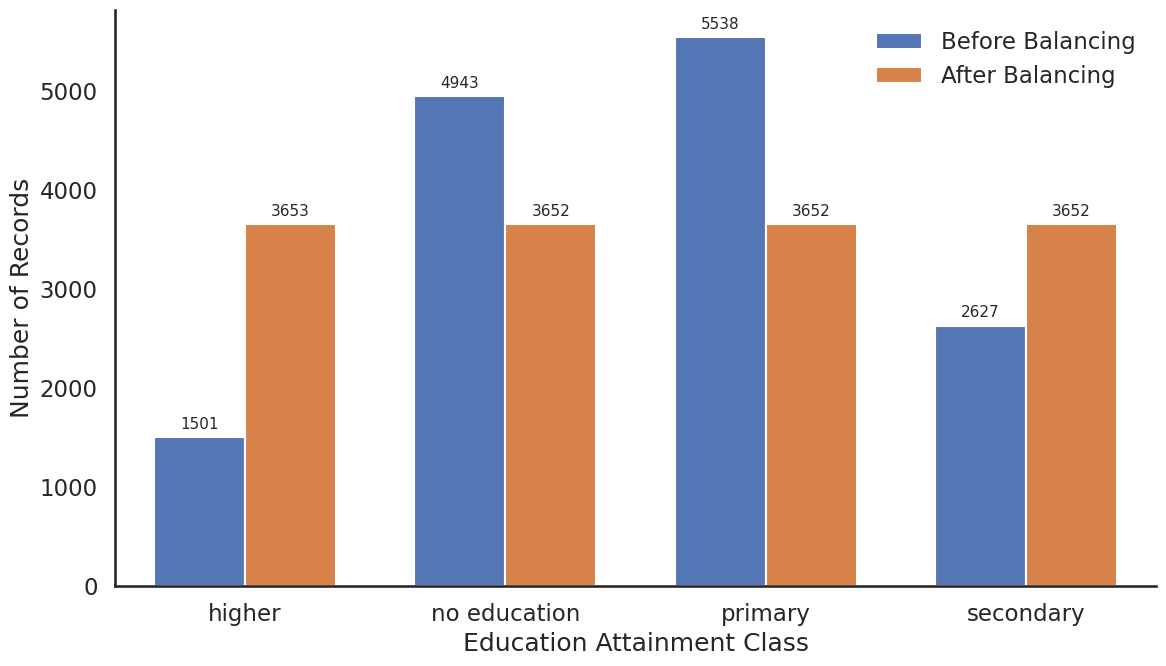

In [ ]:
sns.set_theme(style="white", context="talk")

fig, ax = plt.subplots(figsize=(12, 7))

plot_data = distribution.melt(
    id_vars="Education Class",
    var_name="Dataset",
    value_name="Number of Records"
)

sns.barplot(
    data=plot_data,
    x="Education Class",
    y="Number of Records",
    hue="Dataset",
    palette=["#4472C4", "#ED7D31"],
    width=0.7,
    ax=ax
)



ax.set_xlabel("Education Attainment Class")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=11)

ax.legend(title="", frameon=False)

# Remove internal lines and unnecessary borders
ax.grid(False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTETomek
from sklearn.datasets import make_classification
from collections import Counter

# Step 1: Generate imbalanced synthetic data (simulate original dataset)
n_samples = 20870
X, y = make_classification(n_samples=n_samples, n_features=8, n_classes=4,
                           weights=[0.51539, 0.48095,0.51539, 0.48095,], random_state=42)

# Step 2: Define column names
columns = ['Region', 'Age','Place of residence', 'Religion', 'Sex', 'Wealth index', 'Marital status', 'employment Status']


# Step 3: Create DataFrame
df = pd.DataFrame(X, columns=columns)
df['Education Status'] = y

# Step 4: Separate features and target
X = df[columns]
y = df['Education Status']

# ✅ Step 5: Split into train and test before balancing
X_training, X_test, y_training, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# Calculate desired training set size to keep total size equal to original
original_total = len(X)
test_size = len(X_test)
desired_train_size = original_total - test_size  # approx 11475

# Count original minority and majority in training set
train_counter = Counter(y_training)
minority_class = min(train_counter, key=train_counter.get)
majority_class = max(train_counter, key=train_counter.get)
minority_count = train_counter[minority_class]
majority_count = train_counter[majority_class]

# Calculate desired minority count after balancing
desired_minority_count = desired_train_size - majority_count
if desired_minority_count < minority_count:
    print("Desired minority count less than current minority count. No oversampling will be done.")
    desired_minority_count = minority_count

# Calculate sampling strategy ratio for SMOTETomek
sampling_strategy_ratio = desired_minority_count / minority_count
print(f"Original minority count: {minority_count}")
print(f"Desired minority count: {desired_minority_count}")
print(f"Sampling strategy ratio: {sampling_strategy_ratio:.3f}")

# Step 6: Balance training set with controlled sampling strategy
smote_tomek = SMOTETomek(sampling_strategy=sampling_strategy_ratio, random_state=42)
X_train, y_train= smote_tomek.fit_resample(X_training, y_training)

# Step 7: Visualize training set class distribution after balancing
unique, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(8, 6))
plt.bar(unique, counts, color=['green', 'blue'])
plt.xlabel('Target Class')
plt.ylabel('Number of Samples')
plt.title('Class Distribution After SMOTETomek (Training Set Only)')
plt.xticks(unique, ['Incomplete (0)', 'Complete (1)'])
plt.tight_layout()
plt.show()

# Step 8: Print sizes for clarity
print(f"📦 Original dataset size: {original_total}")  # 16,394
print(f"✅ Training set before balancing: {len(X_training)}")
print(f"🧪 Test set (unchanged): {len(X_test)}")
print(f"📊 Balanced training set after SMOTETomek: {len(X_train)}")
print(f"📈 Total dataset size after balancing training only: {len(X_train) + len(X_test)}")


ValueError: n_classes(4) * n_clusters_per_class(2) must be smaller or equal 2**n_informative(2)=4

In [ ]:
# ============================================================
# STEP 9: RECALCULATE EQUAL CLASS TARGET COUNTS
# ============================================================

classes = sorted(np.unique(y_training))

original_train_size = len(X_training)

base = original_train_size // len(classes)
remainder = original_train_size % len(classes)

target_counts = {
    cls: base + (1 if i < remainder else 0)
    for i, cls in enumerate(classes)
}

print("Required class distribution:", target_counts)
print("Required total:", sum(target_counts.values()))


# ============================================================
# STEP 10: SELECT DATASET WITH SUFFICIENT CLASS COUNTS
# ============================================================

smote_counts = Counter(y_smote)
tomek_counts = Counter(y_tomek)

if all(tomek_counts[cls] >= target_counts[cls] for cls in classes):
    X_final = X_tomek
    y_final = y_tomek
    print("\nUsing Tomek-cleaned dataset.")

elif all(smote_counts[cls] >= target_counts[cls] for cls in classes):
    X_final = X_smote
    y_final = y_smote
    print("\nUsing SMOTE dataset.")

else:
    raise ValueError("Neither dataset has sufficient samples for the requested targets.")


# ============================================================
# STEP 11: FINAL CONTROLLED UNDERSAMPLING
# ============================================================

under_sampler = RandomUnderSampler(
    sampling_strategy=target_counts,
    random_state=42
)

X_train, y_train = under_sampler.fit_resample(
    X_final,
    y_final
)


# ============================================================
# STEP 12: VERIFY FINAL DISTRIBUTION
# ============================================================

final_counts = Counter(y_train)

print("\nOriginal training distribution:")
print(Counter(y_training))

print("\nFinal training distribution:")
print(final_counts)

print("\nOriginal training size:", len(X_training))
print("Final training size:", len(X_train))
print("Testing size:", len(X_test))

print("\nClass counts:")
for cls in classes:
    print(f"Class {cls}: {final_counts[cls]}")


# ============================================================
# STEP 13: FINAL VALIDATION
# ============================================================

assert len(X_train) == len(X_training), "Training size changed!"

assert len(X_test) == len(y_test), "Test size mismatch!"

assert all(final_counts[cls] == target_counts[cls] for cls in classes), \
    "Class distribution is not equal to the target!"

print("\nSUCCESS: Original training size preserved.")
print("SUCCESS: All four classes are balanced.")
print("SUCCESS: Test dataset remains unchanged.")

Required class distribution: {np.int64(0): 3653, np.int64(1): 3652, np.int64(2): 3652, np.int64(3): 3652}
Required total: 14609

Using Tomek-cleaned dataset.

Original training distribution:
Counter({2: 5831, 1: 3662, 3: 3638, 0: 1478})

Final training distribution:
Counter({0: 3653, 1: 3652, 2: 3652, 3: 3652})

Original training size: 14609
Final training size: 14609
Testing size: 6261

Class counts:
Class 0: 3653
Class 1: 3652
Class 2: 3652
Class 3: 3652

SUCCESS: Original training size preserved.
SUCCESS: All four classes are balanced.
SUCCESS: Test dataset remains unchanged.


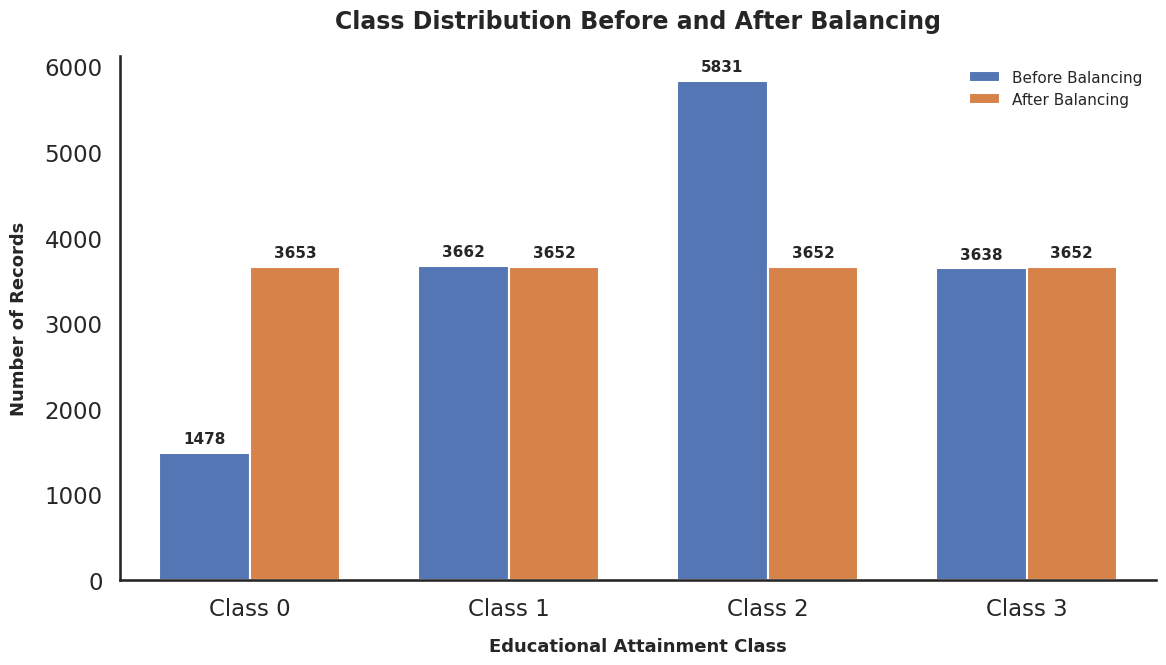


CLASS DISTRIBUTION SUMMARY
Education Class  Before Balancing  After Balancing
        Class 0              1478             3653
        Class 1              3662             3652
        Class 2              5831             3652
        Class 3              3638             3652

Original training records: 14609
Balanced training records: 14609
Testing records: 6261


In [ ]:
# ============================================================
# STEP 14: VISUALIZE CLASS DISTRIBUTION
#         BEFORE AND AFTER BALANCING
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from collections import Counter

# Calculate class distributions
before_counts = Counter(y_training)
after_counts = Counter(y_train)

classes = sorted(before_counts.keys())

# Create distribution DataFrame
distribution = pd.DataFrame({
    "Education Class": [f"Class {c}" for c in classes],
    "Before Balancing": [before_counts[c] for c in classes],
    "After Balancing": [after_counts[c] for c in classes]
})

# ============================================================
# STEP 15: GROUPED BAR CHART
# ============================================================

sns.set_theme(style="white", context="talk")

fig, ax = plt.subplots(figsize=(12, 7))

plot_data = distribution.melt(
    id_vars="Education Class",
    var_name="Dataset",
    value_name="Number of Records"
)

sns.barplot(
    data=plot_data,
    x="Education Class",
    y="Number of Records",
    hue="Dataset",
    palette=["#4472C4", "#ED7D31"],
    width=0.7,
    ax=ax
)

# Axis labels
ax.set_xlabel(
    "Educational Attainment Class",
    fontsize=13,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Number of Records",
    fontsize=13,
    fontweight="bold",
    labelpad=12
)

# Chart title
ax.set_title(
    "Class Distribution Before and After Balancing",
    fontsize=17,
    fontweight="bold",
    pad=20
)

# Display exact sample counts
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=11,
        fontweight="bold"
    )

# Legend
ax.legend(
    title="",
    frameon=False,
    fontsize=11,
    loc="upper right"
)

# Remove internal gridlines and unnecessary borders
ax.grid(False)
sns.despine(ax=ax)

# Improve layout
plt.tight_layout()
plt.show()

# ============================================================
# STEP 16: PRINT DISTRIBUTION SUMMARY
# ============================================================

print("\nCLASS DISTRIBUTION SUMMARY")
print(distribution.to_string(index=False))

print("\nOriginal training records:", len(y_training))
print("Balanced training records:", len(y_train))
print("Testing records:", len(y_test))

## Cell 8 — Build preprocessing
Imputation and encoding are fitted inside the model pipeline, using training data only. Dense one-hot output is used so the tree, boosting, and neural-network learners can all consume the transformed features.

Random Forest training completed successfully.

RANDOM FOREST PERFORMANCE
Accuracy: 0.9152 (91.52%)
Precision: 0.8951 (89.51%)
Recall: 0.9096 (90.96%)
F1-Score: 0.9018 (90.18%)
Training Accuracy: 0.9806 (98.06%)

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.88      0.84       634
           1       0.93      0.93      0.93      1569
           2       0.96      0.91      0.94      2499
           3       0.87      0.91      0.89      1559

    accuracy                           0.92      6261
   macro avg       0.90      0.91      0.90      6261
weighted avg       0.92      0.92      0.92      6261



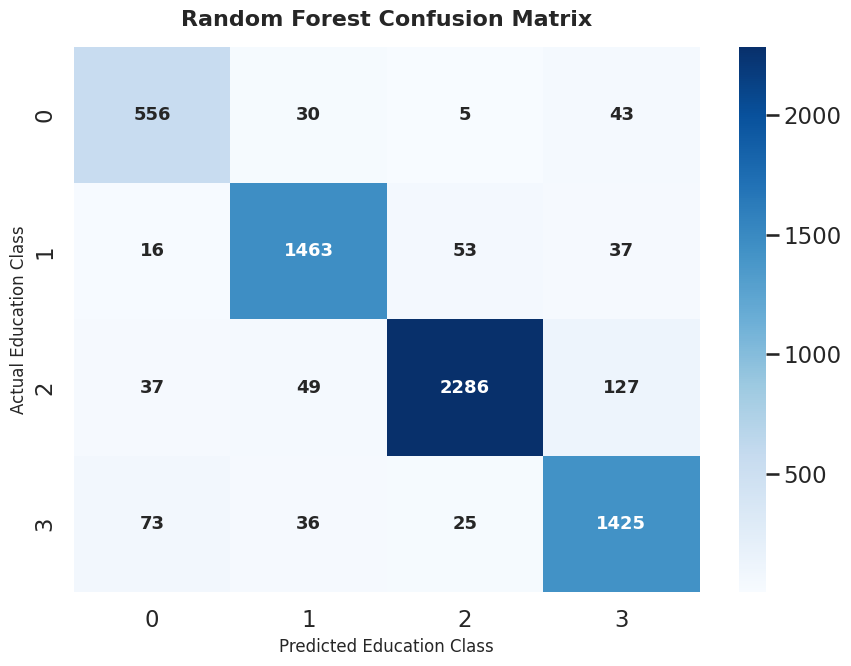


Macro ROC-AUC: 0.9855


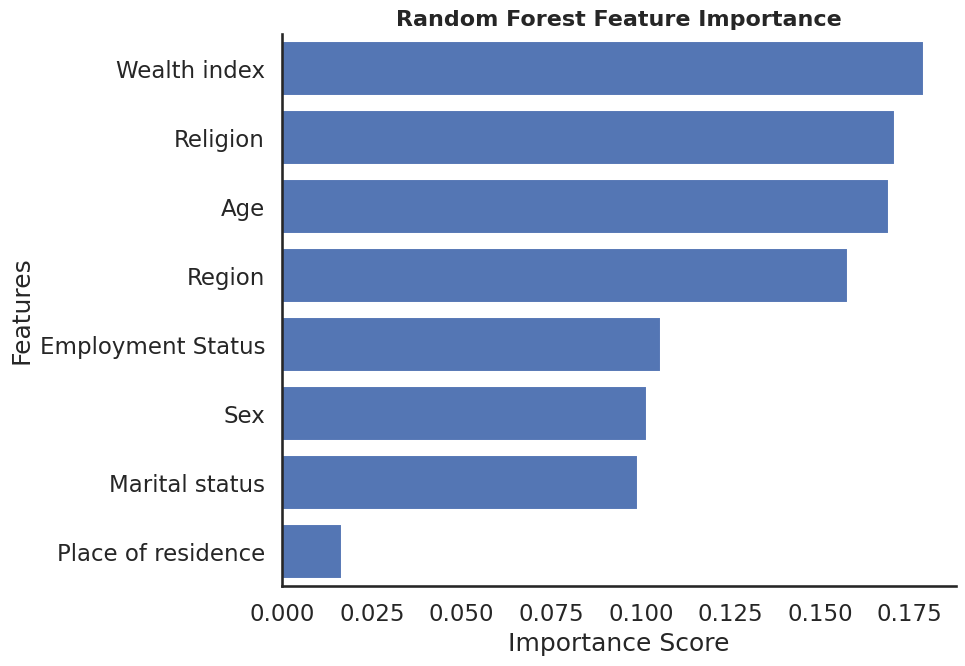

In [ ]:
# ============================================================
# STEP 17: IMPLEMENT RANDOM FOREST CLASSIFIER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully.")

# ============================================================
# STEP 18: MODEL PREDICTION
# ============================================================

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

# ============================================================
# STEP 19: MODEL EVALUATION
# ============================================================

metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "Training Accuracy": accuracy_score(y_train, y_train_pred)
}

print("\nRANDOM FOREST PERFORMANCE")
for metric, value in metrics.items():
    print(f"{metric}: {value:.4f} ({value*100:.2f}%)")

# ============================================================
# STEP 20: CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

# ============================================================
# STEP 21: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    cbar=True,
    xticklabels=sorted(np.unique(y_test)),
    yticklabels=sorted(np.unique(y_test)),
    annot_kws={"size": 13, "weight": "bold"}
)

plt.title(
    "Random Forest Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Education Class", fontsize=12)
plt.ylabel("Actual Education Class", fontsize=12)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 22: MULTICLASS ROC-AUC
# ============================================================

y_test_proba = rf_model.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro"
)

print(f"\nMacro ROC-AUC: {roc_auc:.4f}")

# ============================================================
# STEP 23: FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="#4472C4"
)

plt.title(
    "Random Forest Feature Importance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.grid(False)
sns.despine()

plt.tight_layout()
plt.show()

**Catboost Algorithm**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 27.2 MB/s  0:00:03
0:	learn: 0.7380545	test: 0.7355641	best: 0.7355641 (0)	total: 69.5ms	remaining: 34.7s
100:	learn: 0.8988106	test: 0.8865328	best: 0.8865328 (100)	total: 1.56s	remaining: 6.17s
200:	learn: 0.9176958	test: 0.9030420	best: 0.9030420 (200)	total: 3.08s	remaining: 4.58s
300:	learn: 0.9241950	test: 0.9093646	best: 0.9093816 (291)	total: 4.63s	remaining: 3.06s
400:	learn: 0.9305884	test: 0.9128825	best: 0.9133645 (395)	total: 6.14s	remaining: 1.51s
499:	learn: 0.9340631	test: 0.9163349	best: 0.9163349 (499)	total: 7.5s	remaining: 0us

bestTest = 0.9163348742
bestIteration = 499


CatBoost training completed successfully.

CATBOOST PERFORMANCE
Training Accuracy: 0.9340 (93.40%)
Testing Accuracy: 0.9157 (91.57%)
Precision (Macro): 0.8952 (89.52%)
Recall (Macro): 0.9109 (91.09%)
F1-Score (Macro): 0.9023 (90.23%)

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0

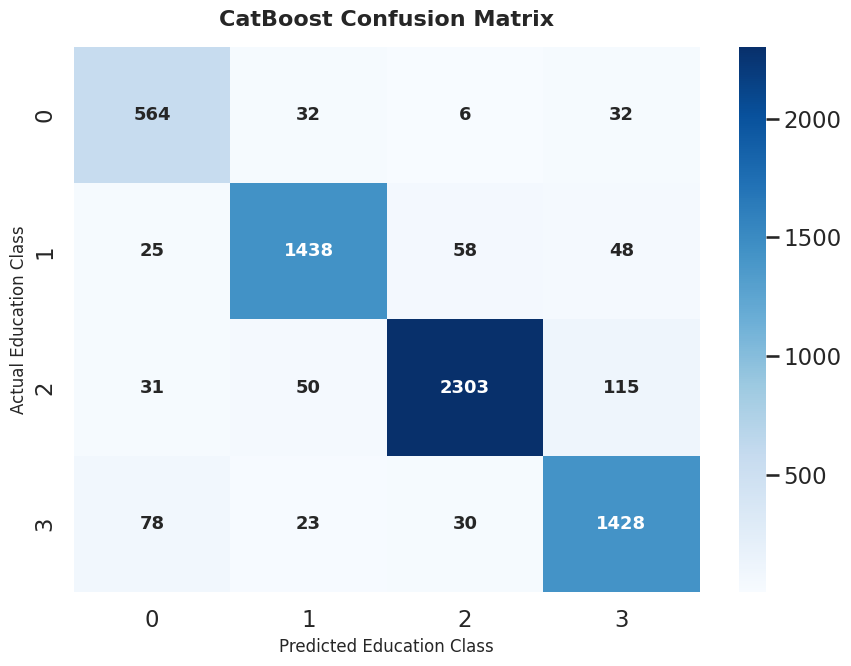


Macro ROC-AUC: 0.9863


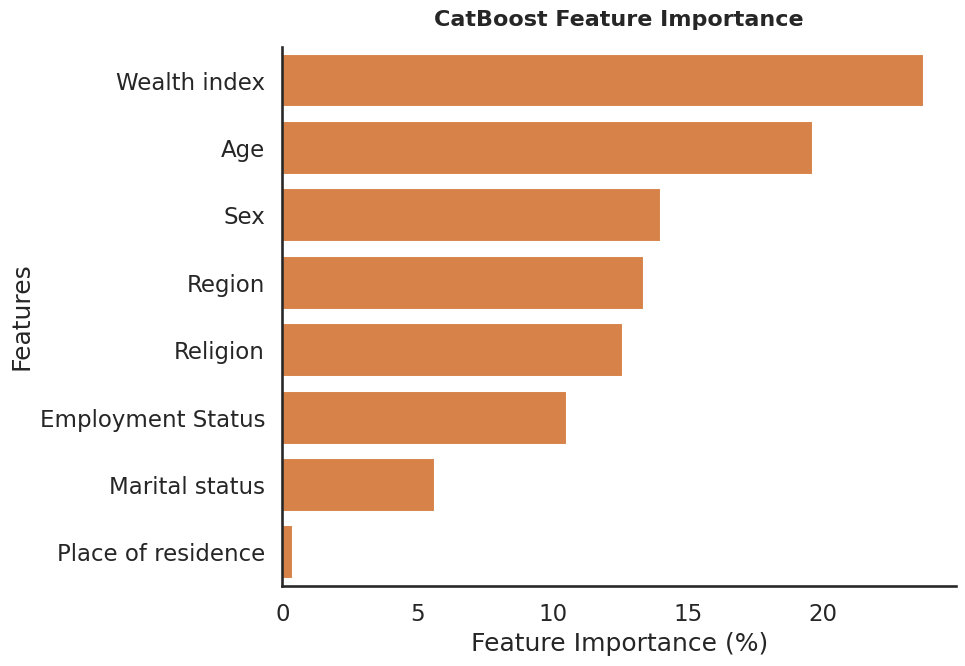

In [ ]:
# ============================================================
# STEP 24: IMPORT CATBOOST AND EVALUATION LIBRARIES
# ============================================================

!pip install catboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# ============================================================
# STEP 25: INITIALIZE CATBOOST CLASSIFIER
# ============================================================

cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.03,
    depth=6,
    loss_function="MultiClass",
    eval_metric="TotalF1",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1
)

# ============================================================
# STEP 26: TRAIN CATBOOST MODEL
# ============================================================

cat_model.fit(
    X_train,
    y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50,
    verbose=100
)

print("\nCatBoost training completed successfully.")

# ============================================================
# STEP 27: MODEL PREDICTION
# ============================================================

y_train_pred = cat_model.predict(X_train).ravel()
y_test_pred = cat_model.predict(X_test).ravel()

# ============================================================
# STEP 28: MODEL EVALUATION
# ============================================================

metrics = {
    "Training Accuracy": accuracy_score(y_train, y_train_pred),
    "Testing Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision (Macro)": precision_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "F1-Score (Macro)": f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    )
}

print("\nCATBOOST PERFORMANCE")

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f} ({value*100:.2f}%)")

# ============================================================
# STEP 29: CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

# ============================================================
# STEP 30: CONFUSION MATRIX
# ============================================================

classes = sorted(np.unique(y_test))

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=classes,
    yticklabels=classes,
    annot_kws={"size": 13, "weight": "bold"}
)

plt.title(
    "CatBoost Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Education Class", fontsize=12)
plt.ylabel("Actual Education Class", fontsize=12)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 31: MULTICLASS ROC-AUC
# ============================================================

y_test_proba = cat_model.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro",
    labels=cat_model.classes_
)

print(f"\nMacro ROC-AUC: {roc_auc:.4f}")

# ============================================================
# STEP 32: FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": cat_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="#ED7D31"
)

plt.title(
    "CatBoost Feature Importance",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Features")

plt.grid(False)
sns.despine()

plt.tight_layout()
plt.show()

XBoost Algorithm

In [ ]:
!pip install xgboost

In [ ]:
# ============================================================
# STEP 33: IMPORT XGBOOST AND EVALUATION LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.preprocessing import LabelEncoder

In [ ]:
# ============================================================
# STEP 34: INITIALIZE XGBOOST CLASSIFIER
# ============================================================

# Encode target classes as consecutive integers
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)
# ============================================================
# STEP 35: TRAIN XGBOOST MODEL
# ============================================================

xgb_model.fit(
    X_train,
    y_train_encoded,
    verbose=False
)

print("XGBoost training completed successfully.")

XGBoost training completed successfully.


In [ ]:
# ============================================================
# STEP 36: MODEL PREDICTION
# ============================================================

y_train_pred_encoded = xgb_model.predict(X_train)
y_test_pred_encoded = xgb_model.predict(X_test)

# Convert predictions back to original class labels
y_train_pred = label_encoder.inverse_transform(
    y_train_pred_encoded.astype(int)
)

y_test_pred = label_encoder.inverse_transform(
    y_test_pred_encoded.astype(int)
)

y_test_proba = xgb_model.predict_proba(X_test)
# ============================================================
# STEP 37: PERFORMANCE EVALUATION
# ============================================================

metrics = {
    "Training Accuracy": accuracy_score(
        y_train, y_train_pred
    ),

    "Testing Accuracy": accuracy_score(
        y_test, y_test_pred
    ),

    "Precision (Macro)": precision_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),

    "Recall (Macro)": recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),

    "F1-Score (Macro)": f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    )
}

print("\nXGBOOST PERFORMANCE")

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f} ({value*100:.2f}%)")

# Multiclass ROC-AUC
roc_auc = roc_auc_score(
    y_test_encoded,
    y_test_proba,
    multi_class="ovr",
    average="macro"
)

print(f"Macro ROC-AUC: {roc_auc:.4f}")


XGBOOST PERFORMANCE
Training Accuracy: 0.9598 (95.98%)
Testing Accuracy: 0.9179 (91.79%)
Precision (Macro): 0.8967 (89.67%)
Recall (Macro): 0.9124 (91.24%)
F1-Score (Macro): 0.9039 (90.39%)
Macro ROC-AUC: 0.9857


In [ ]:
# ============================================================
# STEP 38: CLASSIFICATION REPORT
# ============================================================

print("\nXGBoost Classification Report:\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=label_encoder.classes_,
    zero_division=0
))


XGBoost Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       634
           1       0.93      0.93      0.93      1569
           2       0.96      0.92      0.94      2499
           3       0.88      0.92      0.90      1559

    accuracy                           0.92      6261
   macro avg       0.90      0.91      0.90      6261
weighted avg       0.92      0.92      0.92      6261



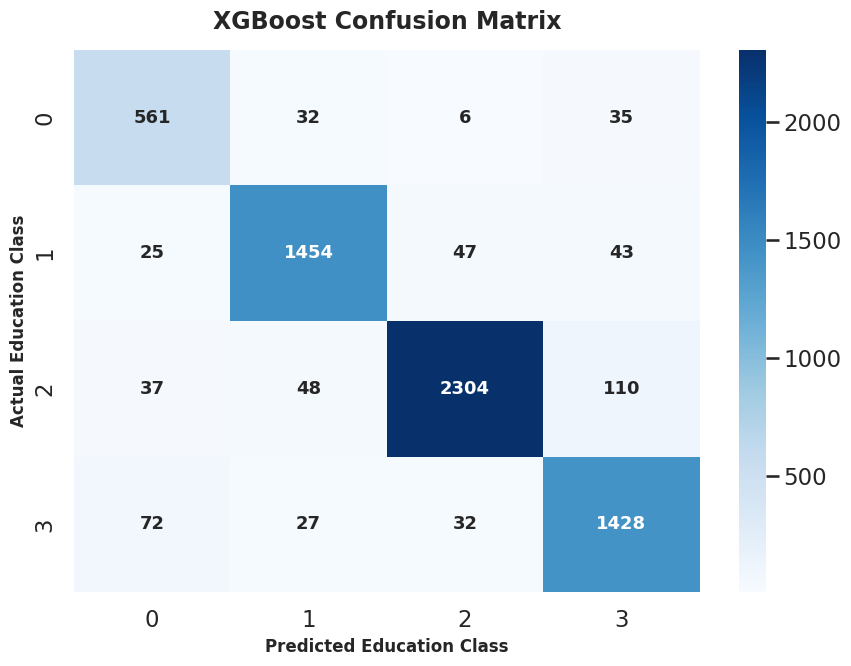

In [ ]:
# ============================================================
# STEP 39: CONFUSION MATRIX
# ============================================================

classes = label_encoder.classes_

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=classes,
    yticklabels=classes,
    annot_kws={
        "size": 13,
        "weight": "bold"
    }
)

plt.title(
    "XGBoost Confusion Matrix",
    fontsize=17,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Predicted Education Class",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Actual Education Class",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

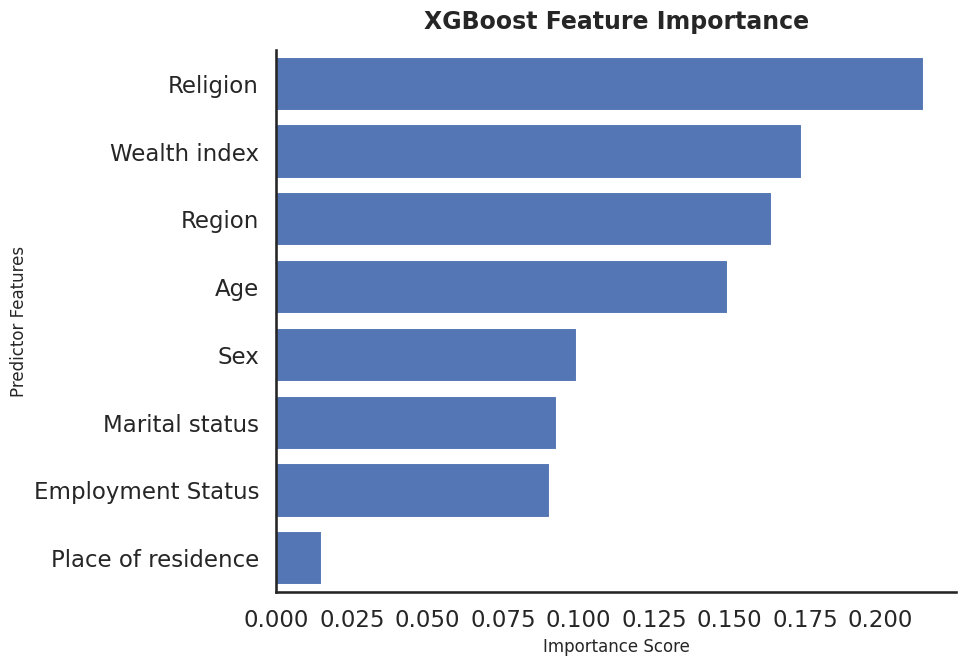


Feature Importance Ranking:
           Feature  Importance
          Religion    0.214235
      Wealth index    0.173881
            Region    0.164204
               Age    0.149505
               Sex    0.099593
    Marital status    0.092954
 Employment Status    0.090427
Place of residence    0.015200


In [ ]:
# ============================================================
# STEP 40: FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="#4472C4"
)

plt.title(
    "XGBoost Feature Importance",
    fontsize=17,
    fontweight="bold",
    pad=15
)

plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Predictor Features", fontsize=12)

plt.grid(False)
sns.despine()

plt.tight_layout()
plt.show()

print("\nFeature Importance Ranking:")
print(feature_importance.to_string(index=False))

**lightgbm Model**

In [ ]:
!pip install lightgbm

In [ ]:
# ============================================================
# LIGHTGBM: MODEL TRAINING AND PREDICTION
# ============================================================

import lightgbm as lgb
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier

# Initialize LightGBM
lgb_model = LGBMClassifier(
    objective="multiclass",
    n_estimators=300,
    learning_rate=0.03,
    max_depth=8,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train model
lgb_model.fit(X_train, y_train)

# Training predictions
y_train_pred_lgb = lgb_model.predict(X_train)

# Testing predictions
y_test_pred_lgb = lgb_model.predict(X_test)

# Prediction probabilities
y_test_proba_lgb = lgb_model.predict_proba(X_test)

print("LightGBM training completed successfully.")

LightGBM training completed successfully.


In [ ]:
# ============================================================
# LIGHTGBM: PERFORMANCE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# Calculate performance metrics
lgb_results = {
    "Model": "LightGBM",

    "Training Accuracy": accuracy_score(
        y_train, y_train_pred_lgb
    ),

    "Testing Accuracy": accuracy_score(
        y_test, y_test_pred_lgb
    ),

    "Precision": precision_score(
        y_test, y_test_pred_lgb,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_test_pred_lgb,
        average="macro",
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_test, y_test_pred_lgb,
        average="macro",
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_test_proba_lgb,
        multi_class="ovr",
        average="macro",
        labels=lgb_model.classes_
    )
}

# Display performance
lgb_results_df = pd.DataFrame([lgb_results])

print("\nLIGHTGBM PERFORMANCE RESULTS\n")

print(
    lgb_results_df.to_string(
        index=False,
        formatters={
            col: "{:.4f}".format
            for col in lgb_results_df.select_dtypes(
                include="number"
            ).columns
        }
    )
)

# Detailed classification report
print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_test_pred_lgb,
    zero_division=0
))


LIGHTGBM PERFORMANCE RESULTS

   Model Training Accuracy Testing Accuracy Precision Recall F1-Score ROC-AUC
LightGBM            0.9711           0.9193    0.8989 0.9141   0.9059  0.9860

CLASSIFICATION REPORT

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       634
           1       0.93      0.92      0.93      1569
           2       0.96      0.92      0.94      2499
           3       0.89      0.92      0.90      1559

    accuracy                           0.92      6261
   macro avg       0.90      0.91      0.91      6261
weighted avg       0.92      0.92      0.92      6261



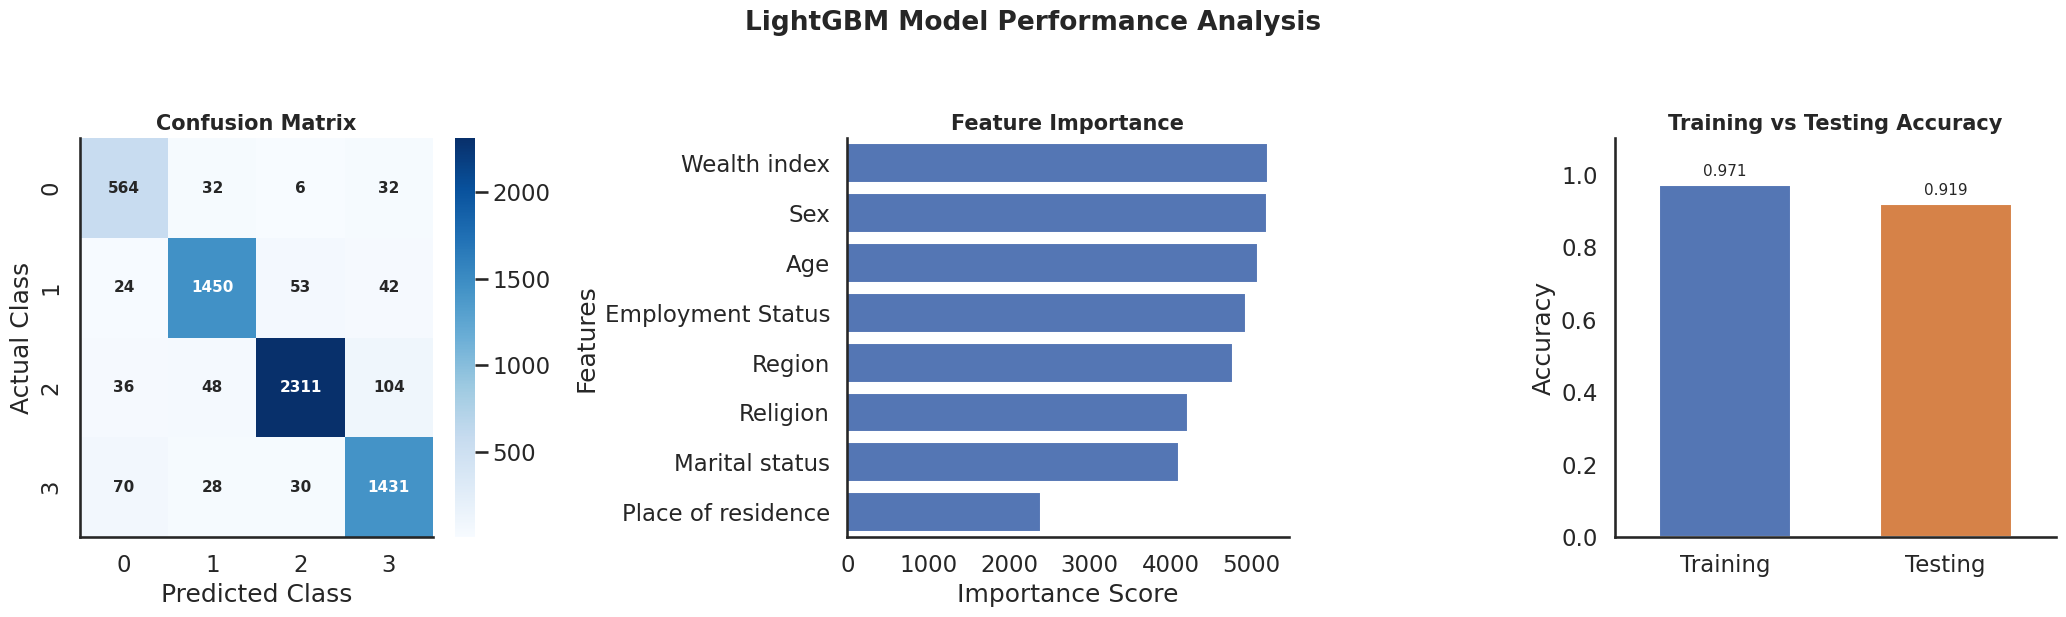

In [ ]:
# ============================================================
# LIGHTGBM: PERFORMANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="white", context="talk")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# ------------------------------------------------------------
# 1. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_test_pred_lgb,
    labels=lgb_model.classes_
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=lgb_model.classes_,
    yticklabels=lgb_model.classes_,
    annot_kws={"size": 11, "weight": "bold"},
    ax=axes[0]
)

axes[0].set_title(
    "Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")


# ------------------------------------------------------------
# 2. FEATURE IMPORTANCE
# ------------------------------------------------------------

feature_importance_lgb = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgb_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

sns.barplot(
    data=feature_importance_lgb,
    x="Importance",
    y="Feature",
    color="#4472C4",
    ax=axes[1]
)

axes[1].set_title(
    "Feature Importance",
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel("Importance Score")
axes[1].set_ylabel("Features")


# ------------------------------------------------------------
# 3. TRAINING VS TESTING ACCURACY
# ------------------------------------------------------------

accuracy_data_lgb = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        lgb_results["Training Accuracy"],
        lgb_results["Testing Accuracy"]
    ]
})

sns.barplot(
    data=accuracy_data_lgb,
    x="Dataset",
    y="Accuracy",
    hue="Dataset",
    palette=["#4472C4", "#ED7D31"],
    legend=False,
    width=0.6,
    ax=axes[2]
)

axes[2].set_title(
    "Training vs Testing Accuracy",
    fontsize=15,
    fontweight="bold"
)

axes[2].set_ylabel("Accuracy")
axes[2].set_xlabel("")
axes[2].set_ylim(0, 1.1)

for container in axes[2].containers:
    axes[2].bar_label(
        container,
        fmt="%.3f",
        padding=4,
        fontsize=11
    )


# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------

for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)

plt.suptitle(
    "LightGBM Model Performance Analysis",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

***Tabnet Model***

In [ ]:
!pip install pytorch-tabnet

In [ ]:
# ============================================================
# TABNET: MODEL TRAINING AND PREDICTION
# ============================================================

import numpy as np
import pandas as pd

from pytorch_tabnet.tab_model import TabNetClassifier

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

# TabNet requires numerical input
X_train_tab = np.asarray(X_train, dtype=np.float32)
X_test_tab = np.asarray(X_test, dtype=np.float32)

# Encode target classes into consecutive integers
tab_encoder = LabelEncoder()

y_train_tab = tab_encoder.fit_transform(
    np.asarray(y_train).ravel()
)

y_test_tab = tab_encoder.transform(
    np.asarray(y_test).ravel()
)

# ------------------------------------------------------------
# 2. CREATE VALIDATION SET FROM TRAINING DATA
# ------------------------------------------------------------

X_fit_tab, X_valid_tab, y_fit_tab, y_valid_tab = train_test_split(
    X_train_tab,
    y_train_tab,
    test_size=0.20,
    random_state=42,
    stratify=y_train_tab
)

# ------------------------------------------------------------
# 3. INITIALIZE TABNET
# ------------------------------------------------------------

tab_model = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.5,
    n_independent=2,
    n_shared=2,
    lambda_sparse=1e-4,
    optimizer_fn=__import__("torch").optim.Adam,
    optimizer_params=dict(lr=0.02),
    mask_type="entmax",
    seed=42,
    verbose=10
)

# ------------------------------------------------------------
# 4. TRAIN TABNET
# ------------------------------------------------------------

tab_model.fit(
    X_train=X_fit_tab,
    y_train=y_fit_tab,

    eval_set=[
        (X_valid_tab, y_valid_tab)
    ],

    eval_name=["valid"],
    eval_metric=["accuracy"],

    max_epochs=100,
    patience=15,

    batch_size=256,
    virtual_batch_size=128,

    num_workers=0,
    drop_last=False
)

print("\nTabNet training completed successfully.")

# ------------------------------------------------------------
# 5. MODEL PREDICTION
# ------------------------------------------------------------

y_train_pred_tab = tab_model.predict(X_train_tab)
y_test_pred_tab = tab_model.predict(X_test_tab)

y_test_proba_tab = tab_model.predict_proba(X_test_tab)

print("Training and testing predictions completed.")

epoch 0  | loss: 0.63434 | valid_accuracy: 0.76626 |  0:00:02s
epoch 10 | loss: 0.25502 | valid_accuracy: 0.93361 |  0:00:22s
epoch 20 | loss: 0.21289 | valid_accuracy: 0.93429 |  0:00:41s
epoch 30 | loss: 0.19421 | valid_accuracy: 0.9473  |  0:00:58s
epoch 40 | loss: 0.19341 | valid_accuracy: 0.94661 |  0:01:16s
epoch 50 | loss: 0.19065 | valid_accuracy: 0.94661 |  0:01:33s

Early stopping occurred at epoch 50 with best_epoch = 35 and best_valid_accuracy = 0.95277

TabNet training completed successfully.
Training and testing predictions completed.


In [ ]:
# ============================================================
# TABNET: PERFORMANCE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

tab_results = {
    "Model": "TabNet",

    "Training Accuracy": accuracy_score(
        y_train_tab,
        y_train_pred_tab
    ),

    "Testing Accuracy": accuracy_score(
        y_test_tab,
        y_test_pred_tab
    ),

    "Precision": precision_score(
        y_test_tab,
        y_test_pred_tab,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_test_tab,
        y_test_pred_tab,
        average="macro",
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_test_tab,
        y_test_pred_tab,
        average="macro",
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test_tab,
        y_test_proba_tab,
        multi_class="ovr",
        average="macro",
        labels=np.arange(len(tab_encoder.classes_))
    )
}

# ------------------------------------------------------------
# 2. DISPLAY RESULTS
# ------------------------------------------------------------

tab_results_df = pd.DataFrame([tab_results])

print("\nTABNET PERFORMANCE RESULTS\n")

print(
    tab_results_df.to_string(
        index=False,
        formatters={
            col: "{:.4f}".format
            for col in tab_results_df.select_dtypes(
                include="number"
            ).columns
        }
    )
)

# ------------------------------------------------------------
# 3. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nTABNET CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test_tab,
        y_test_pred_tab,
        labels=np.arange(len(tab_encoder.classes_)),
        target_names=[
            str(c) for c in tab_encoder.classes_
        ],
        zero_division=0
    )
)


TABNET PERFORMANCE RESULTS

 Model Training Accuracy Testing Accuracy Precision Recall F1-Score ROC-AUC
TabNet            0.9511           0.9358    0.9218 0.9306   0.9260  0.9887

TABNET CLASSIFICATION REPORT

              precision    recall  f1-score   support

           0       0.87      0.91      0.89       634
           1       0.93      0.94      0.93      1569
           2       0.97      0.95      0.96      2499
           3       0.91      0.93      0.92      1559

    accuracy                           0.94      6261
   macro avg       0.92      0.93      0.93      6261
weighted avg       0.94      0.94      0.94      6261



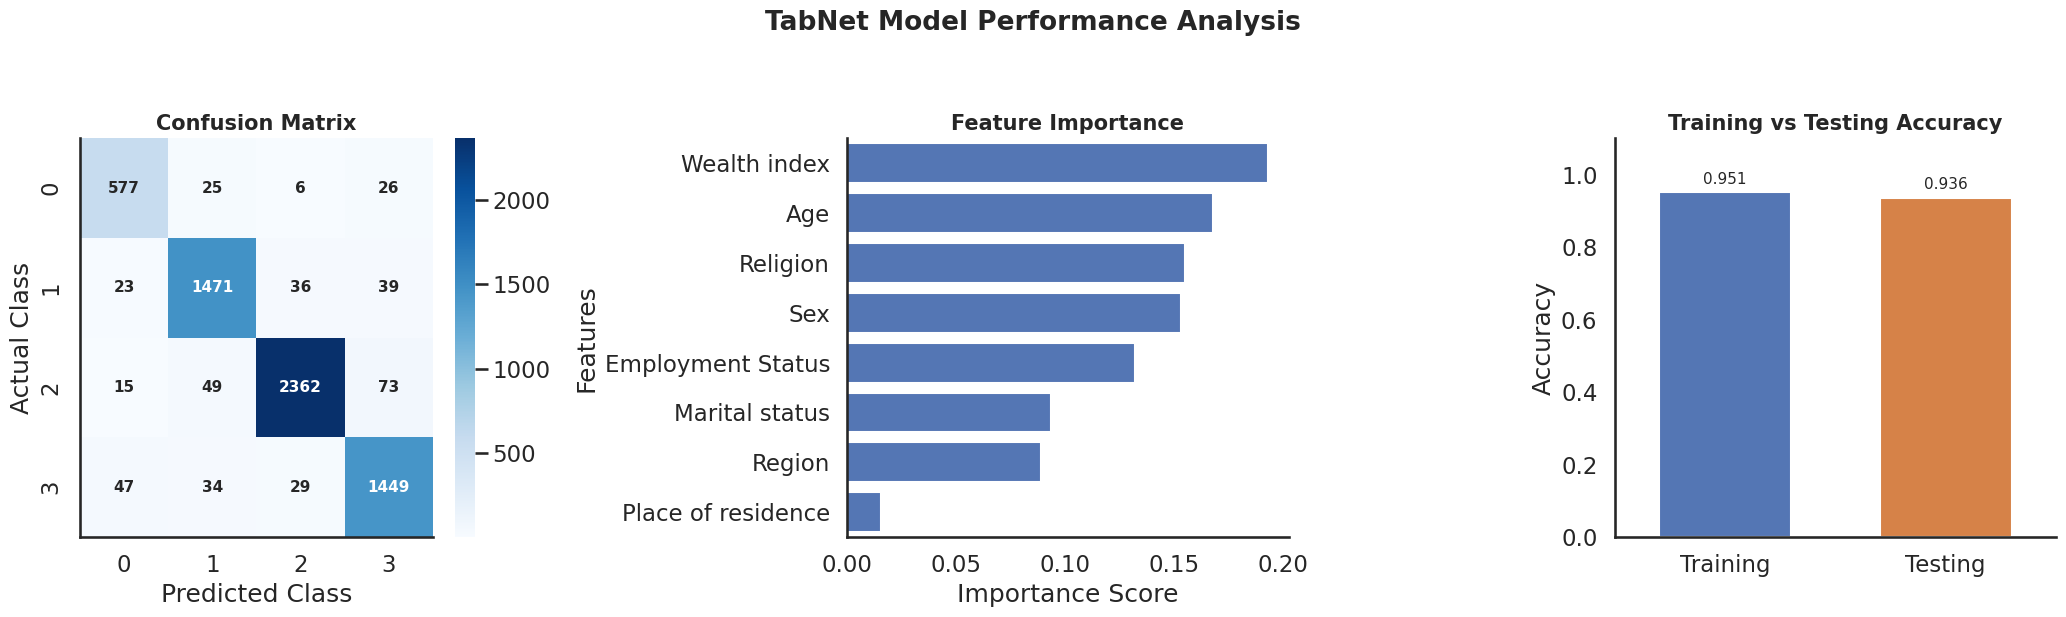


TABNET FEATURE IMPORTANCE RANKING

           Feature  Importance
      Wealth index    0.193109
               Age    0.168066
          Religion    0.154960
               Sex    0.153565
 Employment Status    0.132102
    Marital status    0.093665
            Region    0.088981
Place of residence    0.015553


In [ ]:
# ============================================================
# TABNET: PERFORMANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import confusion_matrix

sns.set_theme(style="white", context="talk")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# ------------------------------------------------------------
# 1. CONFUSION MATRIX
# ------------------------------------------------------------

classes = tab_encoder.classes_

cm = confusion_matrix(
    y_test_tab,
    y_test_pred_tab,
    labels=np.arange(len(classes))
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=classes,
    yticklabels=classes,
    annot_kws={
        "size": 11,
        "weight": "bold"
    },
    ax=axes[0]
)

axes[0].set_title(
    "Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")


# ------------------------------------------------------------
# 2. FEATURE IMPORTANCE
# ------------------------------------------------------------

feature_names = (
    list(X_train.columns)
    if hasattr(X_train, "columns")
    else [f"Feature {i+1}" for i in range(X_train_tab.shape[1])]
)

feature_importance_tab = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tab_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

sns.barplot(
    data=feature_importance_tab,
    x="Importance",
    y="Feature",
    color="#4472C4",
    ax=axes[1]
)

axes[1].set_title(
    "Feature Importance",
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel("Importance Score")
axes[1].set_ylabel("Features")


# ------------------------------------------------------------
# 3. TRAINING VS TESTING ACCURACY
# ------------------------------------------------------------

accuracy_data_tab = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        tab_results["Training Accuracy"],
        tab_results["Testing Accuracy"]
    ]
})

sns.barplot(
    data=accuracy_data_tab,
    x="Dataset",
    y="Accuracy",
    hue="Dataset",
    palette=["#4472C4", "#ED7D31"],
    legend=False,
    width=0.6,
    ax=axes[2]
)

axes[2].set_title(
    "Training vs Testing Accuracy",
    fontsize=15,
    fontweight="bold"
)

axes[2].set_xlabel("")
axes[2].set_ylabel("Accuracy")
axes[2].set_ylim(0, 1.1)

for container in axes[2].containers:
    axes[2].bar_label(
        container,
        fmt="%.3f",
        padding=4,
        fontsize=11
    )


# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------

for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)

plt.suptitle(
    "TabNet Model Performance Analysis",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# PRINT FEATURE IMPORTANCE RANKING
# ------------------------------------------------------------

print("\nTABNET FEATURE IMPORTANCE RANKING\n")

print(
    feature_importance_tab.to_string(index=False)
)

In [ ]:
!pip install shap
# ============================================================
# TABNET: SHAP EXPLAINABILITY ANALYSIS
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PREPARE FEATURE DATA
# ------------------------------------------------------------

feature_names = (
    list(X_train.columns)
    if hasattr(X_train, "columns")
    else [f"Feature_{i+1}" for i in range(X_train_tab.shape[1])]
)

X_test_shap = pd.DataFrame(
    X_test_tab,
    columns=feature_names
)

# Select a manageable background sample
rng = np.random.default_rng(42)

background_idx = rng.choice(
    len(X_train_tab),
    size=min(100, len(X_train_tab)),
    replace=False
)

background = X_train_tab[background_idx]

# ------------------------------------------------------------
# 2. DEFINE TABNET PREDICTION FUNCTION
# ------------------------------------------------------------

def tabnet_predict_proba(data):
    return tab_model.predict_proba(
        np.asarray(data, dtype=np.float32)
    )

# ------------------------------------------------------------
# 3. CALCULATE SHAP VALUES
# ------------------------------------------------------------

explainer = shap.KernelExplainer(
    tabnet_predict_proba,
    background
)

# Limit the number of test samples for computational efficiency
explain_size = min(100, len(X_test_tab))

X_explain = X_test_tab[:explain_size]

shap_values = explainer.shap_values(
    X_explain,
    nsamples=100
)

print("SHAP analysis completed.")

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP analysis completed.


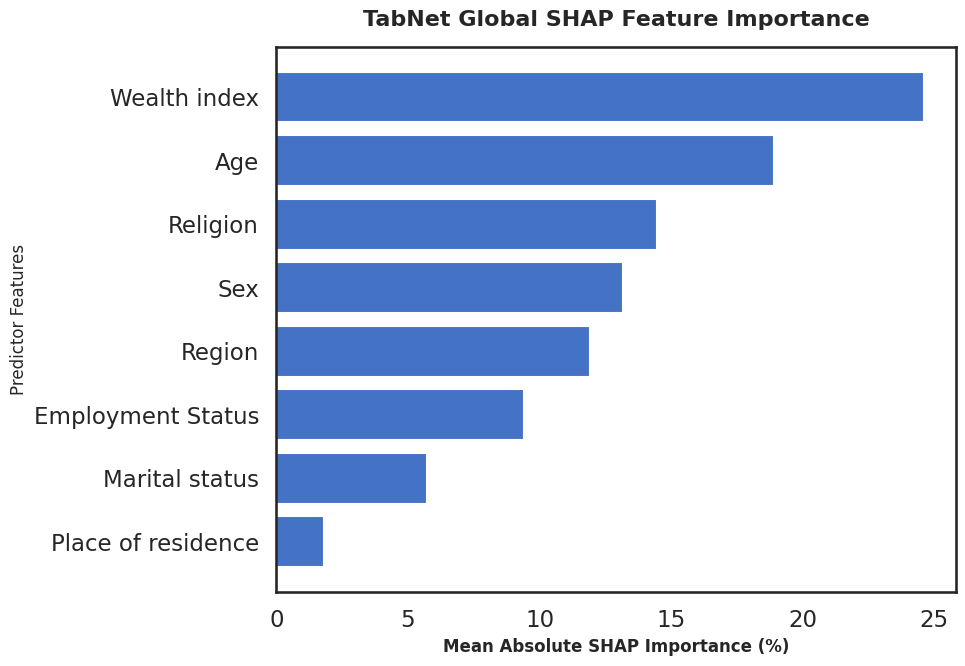


SHAP GLOBAL IMPORTANCE:
           Feature  SHAP Importance (%)
      Wealth index            24.593662
               Age            18.921622
          Religion            14.452084
               Sex            13.178940
            Region            11.926027
 Employment Status             9.406361
    Marital status             5.728815
Place of residence             1.792488


In [ ]:
# ============================================================
# SHAP: GLOBAL FEATURE IMPORTANCE
# ============================================================

# Handle multiclass SHAP output
if isinstance(shap_values, list):

    shap_array = np.stack(
        shap_values,
        axis=-1
    )

else:
    shap_array = np.asarray(shap_values)

# Expected shape: samples x features x classes
if shap_array.ndim != 3:
    raise ValueError(
        f"Unexpected SHAP dimensions: {shap_array.shape}"
    )

# Mean absolute SHAP across samples and classes
mean_shap = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

# Normalize to percentages
shap_percent = (
    mean_shap / mean_shap.sum()
) * 100

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Importance (%)": shap_percent
}).sort_values(
    by="SHAP Importance (%)",
    ascending=False
)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance["SHAP Importance (%)"][::-1],
    color="#4472C4"
)

plt.xlabel(
    "Mean Absolute SHAP Importance (%)",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel("Predictor Features", fontsize=12)

plt.title(
    "TabNet Global SHAP Feature Importance",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.grid(False)
plt.tight_layout()
plt.show()

print("\nSHAP GLOBAL IMPORTANCE:")
print(shap_importance.to_string(index=False))

In [ ]:
!pip install lime
# ============================================================
# TABNET: LIME EXPLAINABILITY ANALYSIS
# ============================================================

from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. INITIALIZE LIME EXPLAINER
# ------------------------------------------------------------

lime_explainer = LimeTabularExplainer(
    training_data=X_train_tab,
    feature_names=feature_names,
    class_names=[
        str(c) for c in tab_encoder.classes_
    ],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# ------------------------------------------------------------
# 2. SELECT TEST OBSERVATION
# ------------------------------------------------------------

sample_index = 0

sample = X_test_tab[sample_index]

predicted_class = int(
    y_test_pred_tab[sample_index]
)

# ------------------------------------------------------------
# 3. GENERATE LIME EXPLANATION
# ------------------------------------------------------------

lime_exp = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=tabnet_predict_proba,
    labels=[predicted_class],
    num_features=len(feature_names),
    num_samples=3000
)

print("LIME explanation generated successfully.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=c697cc76891e02cea643f7160c4fa8357fa4ab15ea46f166aa54f5f649799135
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
LIME explanation generated successfully.


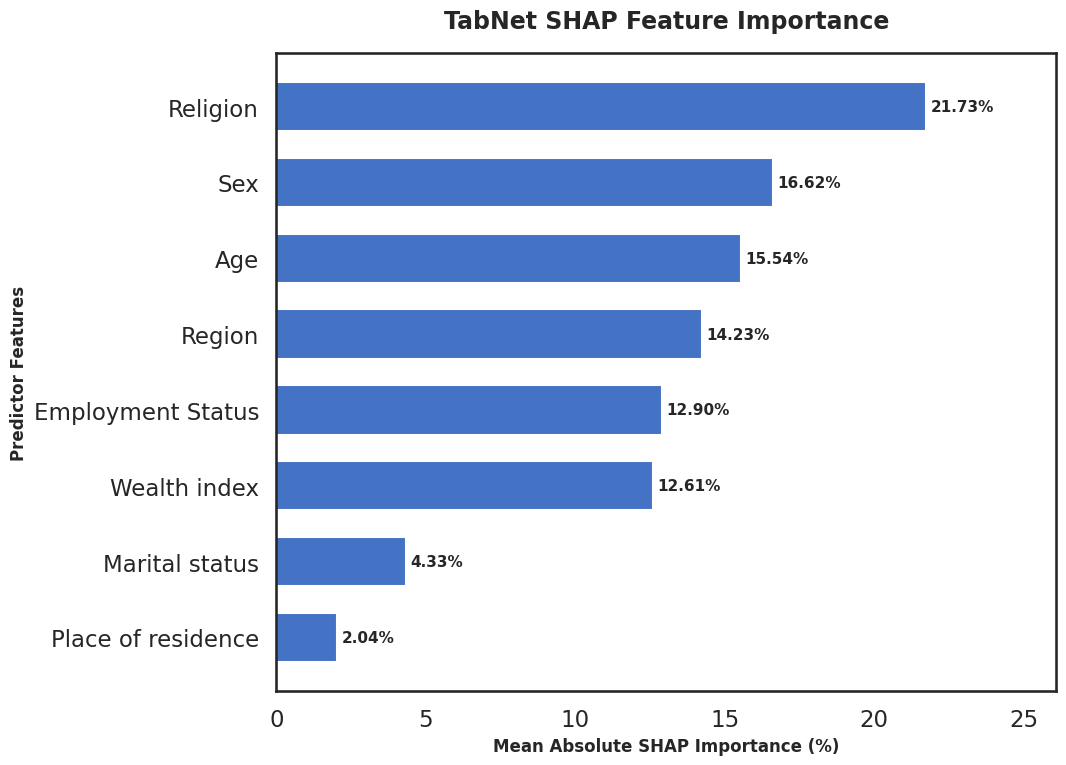


TABNET SHAP FEATURE IMPORTANCE SCORES

           Feature Mean Absolute SHAP Importance Score (%)
          Religion            0.07348               21.73%
               Sex            0.05619               16.62%
               Age            0.05254               15.54%
            Region            0.04809               14.23%
 Employment Status            0.04362               12.90%
      Wealth index            0.04262               12.61%
    Marital status            0.01464                4.33%
Place of residence            0.00691                2.04%

Total importance: 100.00%


In [ ]:
# ============================================================
# TABNET: SHAP IMPORTANCE SCORES WITH VALUE LABELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. EXTRACT CLASS-SPECIFIC SHAP VALUES
# ------------------------------------------------------------

class_index = 0

if isinstance(shap_values, list):
    class_shap = np.asarray(shap_values[class_index])
else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        class_shap = shap_array[:, :, class_index]
    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_array.shape}"
        )

# ------------------------------------------------------------
# 2. CALCULATE FEATURE IMPORTANCE SCORES
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(class_shap),
    axis=0
)

importance_percent = (
    mean_abs_shap / mean_abs_shap.sum()
) * 100

shap_scores = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_abs_shap,
    "Importance Score (%)": importance_percent
})

shap_scores = shap_scores.sort_values(
    by="Importance Score (%)",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. PREPARE VISUALIZATION DATA
# ------------------------------------------------------------

plot_df = shap_scores.sort_values(
    "Importance Score (%)",
    ascending=True
)

# ------------------------------------------------------------
# 4. PLOT FEATURE IMPORTANCE
# ------------------------------------------------------------

plt.figure(figsize=(11, 8))

bars = plt.barh(
    plot_df["Feature"],
    plot_df["Importance Score (%)"],
    color="#4472C4",
    height=0.65
)

# Add exact percentage scores
for bar in bars:

    width = bar.get_width()

    plt.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "TabNet SHAP Feature Importance",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel(
    "Mean Absolute SHAP Importance (%)",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Predictor Features",
    fontsize=12,
    fontweight="bold"
)

plt.xlim(
    0,
    plot_df["Importance Score (%)"].max() * 1.2
)

plt.grid(False)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. PRINT IMPORTANCE SCORES
# ------------------------------------------------------------

print("\nTABNET SHAP FEATURE IMPORTANCE SCORES\n")

print(
    shap_scores.to_string(
        index=False,
        formatters={
            "Mean Absolute SHAP": "{:.5f}".format,
            "Importance Score (%)": "{:.2f}%".format
        }
    )
)

print(
    "\nTotal importance:",
    f"{shap_scores['Importance Score (%)'].sum():.2f}%"
)

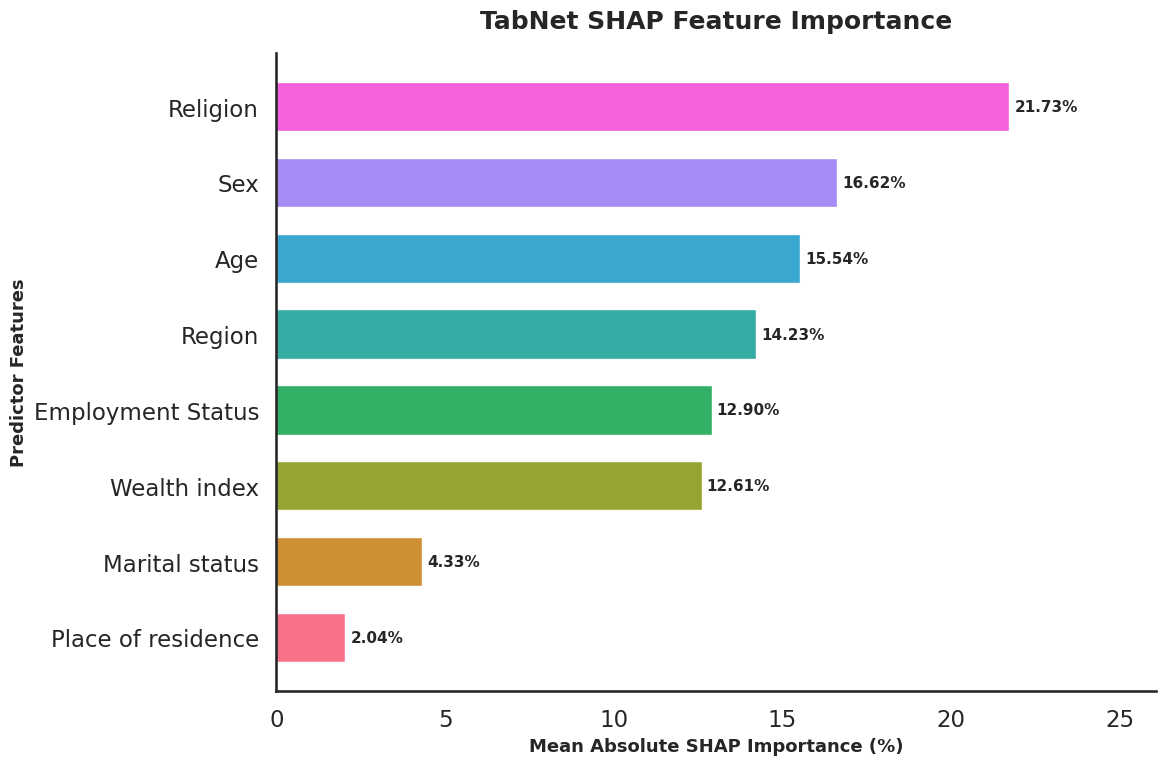


SHAP FEATURE IMPORTANCE SCORES
           Feature Mean Absolute SHAP Importance Score (%)
          Religion            0.07348               21.73%
               Sex            0.05619               16.62%
               Age            0.05254               15.54%
            Region            0.04809               14.23%
 Employment Status            0.04362               12.90%
      Wealth index            0.04262               12.61%
    Marital status            0.01464                4.33%
Place of residence            0.00691                2.04%


In [ ]:
# ============================================================
# TABNET: SHAP IMPORTANCE WITH DIFFERENT FEATURE COLORS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Sort features by importance
plot_df = shap_scores.sort_values(
    "Importance Score (%)",
    ascending=True
).copy()

# Generate a unique color for every feature
colors = sns.color_palette(
    "husl",
    n_colors=len(plot_df)
)

# Create visualization
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_df["Feature"],
    plot_df["Importance Score (%)"],
    color=colors,
    height=0.65,
    edgecolor="white",
    linewidth=1
)

# Add numerical importance scores
for bar in bars:

    width = bar.get_width()

    ax.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold"
    )

# Titles and labels
ax.set_title(
    "TabNet SHAP Feature Importance",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Mean Absolute SHAP Importance (%)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor Features",
    fontsize=13,
    fontweight="bold"
)

# Clean visualization
ax.set_xlim(
    0,
    plot_df["Importance Score (%)"].max() * 1.20
)

ax.grid(False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# Display numerical results
print("\nSHAP FEATURE IMPORTANCE SCORES")

print(
    shap_scores.to_string(
        index=False,
        formatters={
            "Mean Absolute SHAP": "{:.5f}".format,
            "Importance Score (%)": "{:.2f}%".format
        }
    )
)

HISTGRADIENTBOOSTING Model
**bold text**


In [ ]:
# ============================================================
# HISTGRADIENTBOOSTING: MODEL TRAINING AND PREDICTION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier

# Initialize model
hgb_model = HistGradientBoostingClassifier(
    loss="log_loss",
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    max_depth=None,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=42
)

# Train model
hgb_model.fit(X_train, y_train)

# Training predictions
y_train_pred_hgb = hgb_model.predict(X_train)

# Testing predictions
y_test_pred_hgb = hgb_model.predict(X_test)

# Prediction probabilities
y_test_proba_hgb = hgb_model.predict_proba(X_test)

print("HistGradientBoosting training completed successfully.")

HistGradientBoosting training completed successfully.


In [ ]:
# ============================================================
# HISTGRADIENTBOOSTING: PERFORMANCE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

hgb_results = {
    "Model": "HistGradientBoosting",

    "Training Accuracy": accuracy_score(
        y_train, y_train_pred_hgb
    ),

    "Testing Accuracy": accuracy_score(
        y_test, y_test_pred_hgb
    ),

    "Precision": precision_score(
        y_test, y_test_pred_hgb,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_test_pred_hgb,
        average="macro",
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_test, y_test_pred_hgb,
        average="macro",
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_test_proba_hgb,
        multi_class="ovr",
        average="macro",
        labels=hgb_model.classes_
    )
}

# Display results
hgb_results_df = pd.DataFrame([hgb_results])

print("\nHISTGRADIENTBOOSTING PERFORMANCE RESULTS\n")

print(
    hgb_results_df.to_string(
        index=False,
        formatters={
            col: "{:.4f}".format
            for col in hgb_results_df.select_dtypes(
                include="number"
            ).columns
        }
    )
)

# Classification report
print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_test_pred_hgb,
    zero_division=0
))


HISTGRADIENTBOOSTING PERFORMANCE RESULTS

               Model Training Accuracy Testing Accuracy Precision Recall F1-Score ROC-AUC
HistGradientBoosting            0.9895           0.9205    0.9028 0.9134   0.9078  0.9863

CLASSIFICATION REPORT

              precision    recall  f1-score   support

           0       0.84      0.88      0.86       634
           1       0.93      0.93      0.93      1569
           2       0.96      0.93      0.94      2499
           3       0.88      0.92      0.90      1559

    accuracy                           0.92      6261
   macro avg       0.90      0.91      0.91      6261
weighted avg       0.92      0.92      0.92      6261



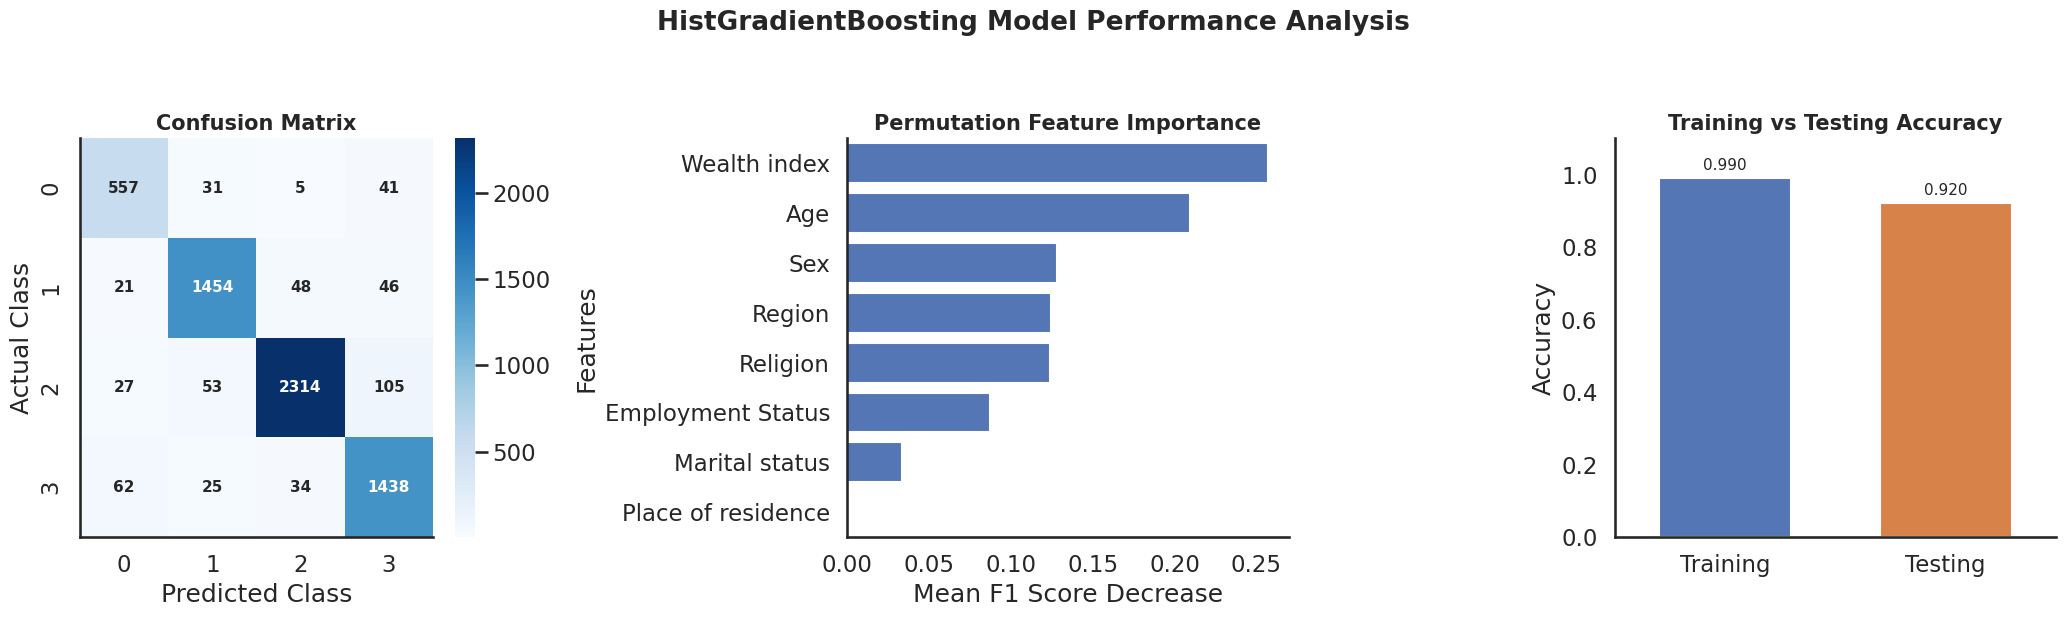


FEATURE IMPORTANCE RANKING

           Feature  Importance
      Wealth index    0.256859
               Age    0.209711
               Sex    0.128031
            Region    0.124318
          Religion    0.123623
 Employment Status    0.087397
    Marital status    0.033188
Place of residence    0.000513


In [ ]:
# ============================================================
# HISTGRADIENTBOOSTING: PERFORMANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix

sns.set_theme(style="white", context="talk")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# ------------------------------------------------------------
# 1. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_test_pred_hgb,
    labels=hgb_model.classes_
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=hgb_model.classes_,
    yticklabels=hgb_model.classes_,
    annot_kws={"size": 11, "weight": "bold"},
    ax=axes[0]
)

axes[0].set_title(
    "Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")


# ------------------------------------------------------------
# 2. PERMUTATION FEATURE IMPORTANCE
# ------------------------------------------------------------

perm_result = permutation_importance(
    hgb_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_names = (
    X_train.columns.tolist()
    if hasattr(X_train, "columns")
    else [f"Feature {i+1}" for i in range(X_train.shape[1])]
)

hgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_result.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

sns.barplot(
    data=hgb_importance,
    x="Importance",
    y="Feature",
    color="#4472C4",
    ax=axes[1]
)

axes[1].set_title(
    "Permutation Feature Importance",
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel("Mean F1 Score Decrease")
axes[1].set_ylabel("Features")


# ------------------------------------------------------------
# 3. TRAINING VS TESTING ACCURACY
# ------------------------------------------------------------

accuracy_data = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        hgb_results["Training Accuracy"],
        hgb_results["Testing Accuracy"]
    ]
})

sns.barplot(
    data=accuracy_data,
    x="Dataset",
    y="Accuracy",
    hue="Dataset",
    palette=["#4472C4", "#ED7D31"],
    legend=False,
    width=0.6,
    ax=axes[2]
)

axes[2].set_title(
    "Training vs Testing Accuracy",
    fontsize=15,
    fontweight="bold"
)

axes[2].set_xlabel("")
axes[2].set_ylabel("Accuracy")
axes[2].set_ylim(0, 1.1)

for container in axes[2].containers:
    axes[2].bar_label(
        container,
        fmt="%.3f",
        padding=4,
        fontsize=11
    )


# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------

for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)

plt.suptitle(
    "HistGradientBoosting Model Performance Analysis",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

print("\nFEATURE IMPORTANCE RANKING\n")
print(hgb_importance.to_string(index=False))

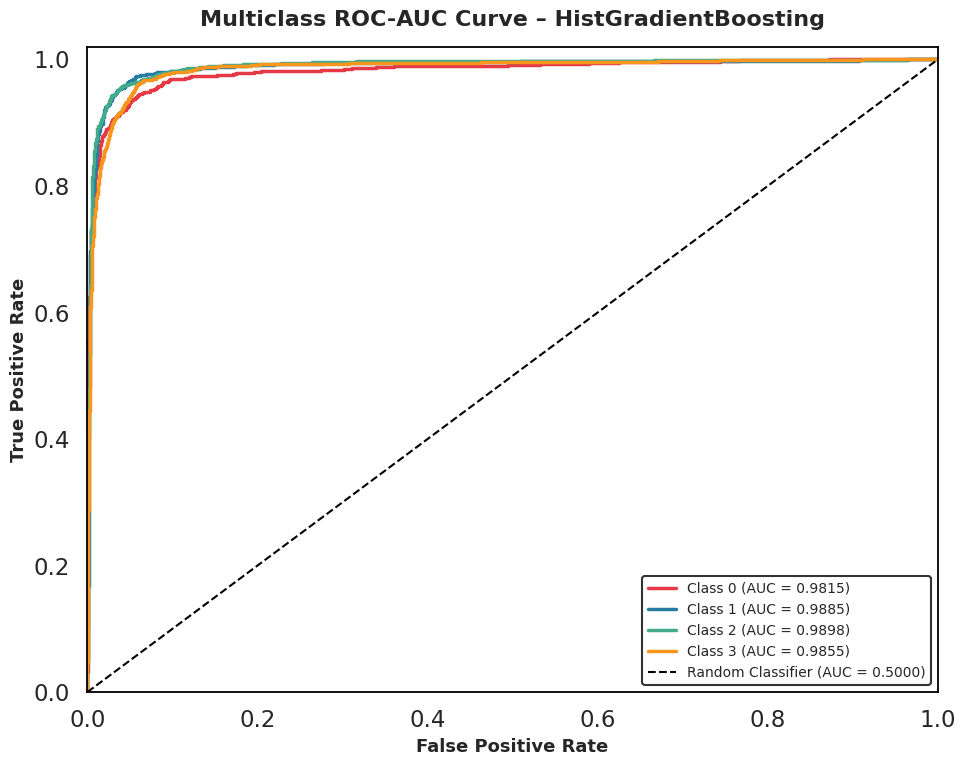


HISTGRADIENTBOOSTING ROC-AUC RESULTS

Class 0 ROC-AUC: 0.9815
Class 1 ROC-AUC: 0.9885
Class 2 ROC-AUC: 0.9898
Class 3 ROC-AUC: 0.9855

Macro-Average ROC-AUC: 0.9863
  Class  ROC-AUC
Class 0 0.981500
Class 1 0.988508
Class 2 0.989843
Class 3 0.985514

Macro-Average ROC-AUC: 0.9863


In [ ]:
# ============================================================
# HISTGRADIENTBOOSTING: MULTICLASS ROC-AUC CURVE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. BINARIZE TEST LABELS
# ------------------------------------------------------------

classes = hgb_model.classes_
n_classes = len(classes)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 2. CALCULATE ROC CURVES FOR EACH CLASS
# ------------------------------------------------------------

fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_test_proba_hgb[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# ------------------------------------------------------------
# 3. CALCULATE MACRO-AVERAGE ROC-AUC
# ------------------------------------------------------------

macro_auc = roc_auc_score(
    y_test,
    y_test_proba_hgb,
    multi_class="ovr",
    average="macro",
    labels=classes
)

# ------------------------------------------------------------
# 4. VISUALIZE ROC CURVES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

colors = [
    "#E63946",
    "#277DA1",
    "#43AA8B",
    "#F8961E"
]

for i, color in zip(range(n_classes), colors):

    ax.plot(
        fpr[i],
        tpr[i],
        color=color,
        linewidth=2.5,
        label=(
            f"Class {classes[i]} "
            f"(AUC = {roc_auc[i]:.4f})"
        )
    )

# Random classifier reference
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.5000)"
)

# ------------------------------------------------------------
# 5. CHART FORMATTING
# ------------------------------------------------------------

ax.set_title(
    "Multiclass ROC-AUC Curve – HistGradientBoosting",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=True,
    edgecolor="black"
)

# Complete rectangular boundary
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.3)

ax.grid(False)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. PRINT AUC RESULTS
# ------------------------------------------------------------

print("\nHISTGRADIENTBOOSTING ROC-AUC RESULTS\n")

for i in range(n_classes):
    print(
        f"Class {classes[i]} ROC-AUC: {roc_auc[i]:.4f}"
    )

print(f"\nMacro-Average ROC-AUC: {macro_auc:.4f}")
# ============================================================
# HGB: ROC-AUC NUMERICAL SUMMARY
# ============================================================

import pandas as pd

roc_summary_hgb = pd.DataFrame({
    "Class": [f"Class {c}" for c in classes],
    "ROC-AUC": [
        roc_auc[i] for i in range(n_classes)
    ]
})

print(roc_summary_hgb.to_string(index=False))

print("\nMacro-Average ROC-AUC:", round(macro_auc, 4))

PermutationExplainer explainer: 101it [00:21,  2.50it/s]


HistGradientBoosting SHAP calculation completed.
SHAP dimensions: (100, 8, 4)


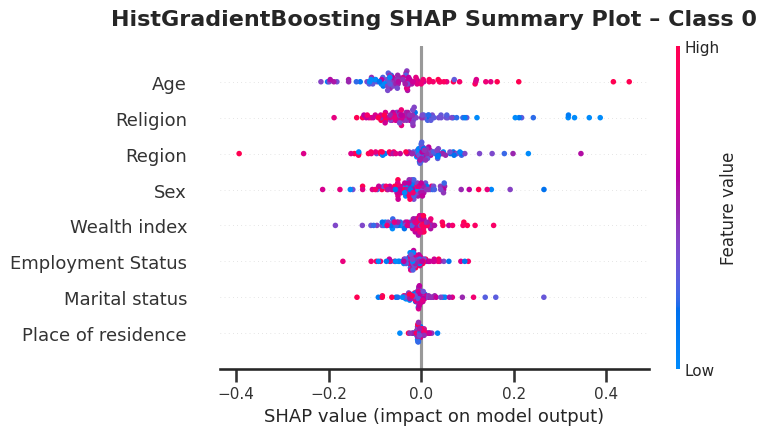

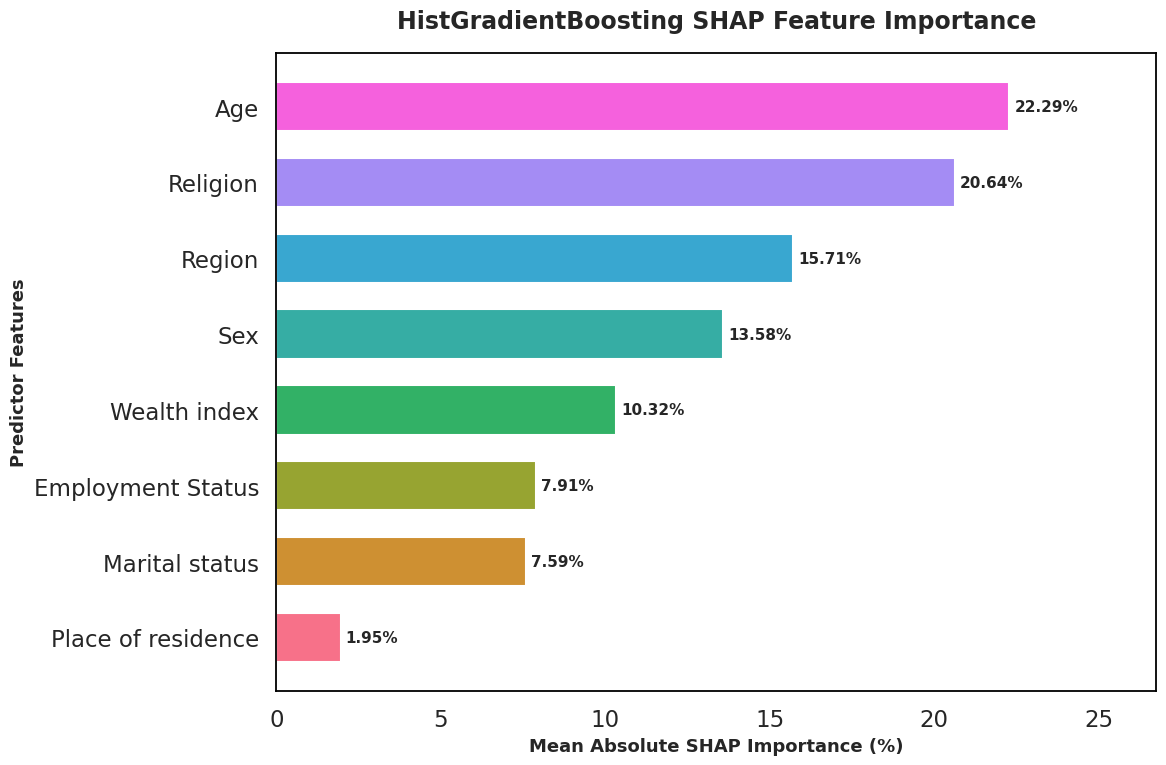


HISTGRADIENTBOOSTING SHAP IMPORTANCE SCORES

           Feature Mean Absolute SHAP Importance Score (%)
               Age            0.08069               22.29%
          Religion            0.07471               20.64%
            Region            0.05687               15.71%
               Sex            0.04917               13.58%
      Wealth index            0.03737               10.32%
 Employment Status            0.02862                7.91%
    Marital status            0.02747                7.59%
Place of residence            0.00707                1.95%

Total SHAP importance: 100.00%


In [ ]:
# ============================================================
# HISTGRADIENTBOOSTING: SHAP VALUE CALCULATION
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Feature names
feature_names = (
    X_train.columns.tolist()
    if hasattr(X_train, "columns")
    else [f"Feature_{i+1}" for i in range(X_train.shape[1])]
)

# Convert data to DataFrames
X_train_shap = pd.DataFrame(
    X_train,
    columns=feature_names
)

X_test_shap = pd.DataFrame(
    X_test,
    columns=feature_names
)

# Select background and explanation samples
rng = np.random.default_rng(42)

background_idx = rng.choice(
    len(X_train_shap),
    size=min(50, len(X_train_shap)),
    replace=False
)

explain_idx = rng.choice(
    len(X_test_shap),
    size=min(100, len(X_test_shap)),
    replace=False
)

background = X_train_shap.iloc[background_idx]
X_explain_hgb = X_test_shap.iloc[explain_idx]

# Select class to explain
class_index = 0

# SHAP explainer
hgb_explainer = shap.Explainer(
    hgb_model.predict_proba,
    masker=shap.maskers.Independent(background),
    algorithm="permutation"
)

# Calculate SHAP values
hgb_shap_values = hgb_explainer(
    X_explain_hgb,
    max_evals=2 * len(feature_names) + 1
)

print("HistGradientBoosting SHAP calculation completed.")
print("SHAP dimensions:", hgb_shap_values.values.shape)
# ============================================================
# HGB: SHAP BEESWARM VISUALIZATION
# ============================================================

# Extract selected class SHAP values
if hgb_shap_values.values.ndim == 3:
    class_shap_hgb = hgb_shap_values.values[:, :, class_index]
else:
    class_shap_hgb = hgb_shap_values.values

# Create SHAP Explanation object
class_explanation_hgb = shap.Explanation(
    values=class_shap_hgb,
    data=X_explain_hgb.values,
    feature_names=feature_names
)

# Beeswarm plot
plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    class_explanation_hgb,
    max_display=len(feature_names),
    show=False,
    color_bar=True
)

plt.title(
    f"HistGradientBoosting SHAP Summary Plot – Class {hgb_model.classes_[class_index]}",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()
# ============================================================
# HGB: SHAP FEATURE IMPORTANCE WITH NUMERICAL SCORES
# ============================================================

import seaborn as sns

# Calculate mean absolute SHAP values
mean_abs_shap_hgb = np.mean(
    np.abs(class_shap_hgb),
    axis=0
)

# Calculate percentage importance
importance_percent_hgb = (
    mean_abs_shap_hgb /
    mean_abs_shap_hgb.sum()
) * 100

# Create importance dataframe
hgb_shap_scores = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_abs_shap_hgb,
    "Importance Score (%)": importance_percent_hgb
})

# Sort by importance
hgb_shap_scores = hgb_shap_scores.sort_values(
    by="Importance Score (%)",
    ascending=False
).reset_index(drop=True)

# Prepare plotting data
plot_df = hgb_shap_scores.sort_values(
    "Importance Score (%)",
    ascending=True
)

# Generate a different color for each feature
colors = sns.color_palette(
    "husl",
    n_colors=len(plot_df)
)

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_df["Feature"],
    plot_df["Importance Score (%)"],
    color=colors,
    height=0.65
)

# Add numerical scores
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold"
    )

# Titles and labels
ax.set_title(
    "HistGradientBoosting SHAP Feature Importance",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Mean Absolute SHAP Importance (%)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor Features",
    fontsize=13,
    fontweight="bold"
)

# Set boundaries
ax.set_xlim(
    0,
    plot_df["Importance Score (%)"].max() * 1.20
)

# Complete uniform rectangular boundary
for spine in ["top", "bottom", "left", "right"]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_color("black")
    ax.spines[spine].set_linewidth(1.3)

ax.grid(False)

plt.tight_layout()
plt.show()

# Display numerical scores
print("\nHISTGRADIENTBOOSTING SHAP IMPORTANCE SCORES\n")

print(
    hgb_shap_scores.to_string(
        index=False,
        formatters={
            "Mean Absolute SHAP": "{:.5f}".format,
            "Importance Score (%)": "{:.2f}%".format
        }
    )
)

print(
    "\nTotal SHAP importance:",
    f"{hgb_shap_scores['Importance Score (%)'].sum():.2f}%"
)

Stacking Model

In [ ]:
# ============================================================
# STACKING ENSEMBLE: MODEL TRAINING AND PREDICTION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier
)

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import StratifiedKFold

from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ------------------------------------------------------------
# 1. DEFINE BASE LEARNERS
# ------------------------------------------------------------

base_estimators = [

    ("RF", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )),

    ("ET", ExtraTreesClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )),

    ("CAT", CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.03,
        loss_function="MultiClass",
        verbose=0,
        random_seed=42,
        thread_count=1
    )),

    ("XGB", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1
    )),

    ("LGBM", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=8,
        class_weight=None,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    )),

    ("HGB", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ))
]

# ------------------------------------------------------------
# 2. DEFINE META-LEARNER
# ------------------------------------------------------------

meta_learner = LogisticRegression(
    C=1.0,
    max_iter=2000,
    class_weight=None,
    random_state=42
)

# ------------------------------------------------------------
# 3. STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 4. INITIALIZE STACKING CLASSIFIER
# ------------------------------------------------------------

stack_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=cv_strategy,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1
)

# ------------------------------------------------------------
# 5. TRAIN STACKING MODEL
# ------------------------------------------------------------

stack_model.fit(X_train, y_train)

print("Stacking ensemble training completed successfully.")

# ------------------------------------------------------------
# 6. PREDICTIONS
# ------------------------------------------------------------

y_train_pred_stack = stack_model.predict(X_train)

y_test_pred_stack = stack_model.predict(X_test)

y_test_proba_stack = stack_model.predict_proba(X_test)

print("Training and testing predictions completed.")

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of base learners:", len(base_estimators))

Stacking ensemble training completed successfully.
Training and testing predictions completed.
Training records: 14609
Testing records: 6261
Number of base learners: 6


In [119]:
# ============================================================
# STACKING ENSEMBLE: PERFORMANCE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# ------------------------------------------------------------
# 1. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

stack_results = {
    "Model": "Stacking Ensemble",

    "Training Accuracy": accuracy_score(
        y_train,
        y_train_pred_stack
    ),

    "Testing Accuracy": accuracy_score(
        y_test,
        y_test_pred_stack
    ),

    "Precision": precision_score(
        y_test,
        y_test_pred_stack,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        y_test_pred_stack,
        average="macro",
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_test,
        y_test_pred_stack,
        average="macro",
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_test_proba_stack,
        multi_class="ovr",
        average="macro",
        labels=stack_model.classes_
    )
}

# ------------------------------------------------------------
# 2. DISPLAY PERFORMANCE RESULTS
# ------------------------------------------------------------

stack_results_df = pd.DataFrame([stack_results])

print("\nSTACKING ENSEMBLE PERFORMANCE RESULTS\n")

print(
    stack_results_df.to_string(
        index=False,
        formatters={
            col: "{:.4f}".format
            for col in stack_results_df.select_dtypes(
                include="number"
            ).columns
        }
    )
)

# ------------------------------------------------------------
# 3. DETAILED CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nSTACKING CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        y_test_pred_stack,
        labels=stack_model.classes_,
        zero_division=0
    )
)


STACKING ENSEMBLE PERFORMANCE RESULTS

            Model Training Accuracy Testing Accuracy Precision Recall F1-Score ROC-AUC
Stacking Ensemble            0.9902           0.9214    0.9066 0.9105   0.9083  0.9851

STACKING CLASSIFICATION REPORT

              precision    recall  f1-score   support

           0       0.86      0.85      0.86       634
           1       0.93      0.93      0.93      1569
           2       0.97      0.93      0.95      2499
           3       0.88      0.93      0.90      1559

    accuracy                           0.92      6261
   macro avg       0.91      0.91      0.91      6261
weighted avg       0.92      0.92      0.92      6261



In [122]:
# ============================================================
# FIVE-FOLD CROSS-VALIDATION ROC-AUC VISUALIZATION
# ============================================================

fold_names = [f"Fold {i}" for i in range(1, 6)]

fold_scores = np.array(cv_auc_scores)

mean_auc = np.mean(fold_scores)
std_auc = np.std(fold_scores, ddof=1)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    fold_names,
    fold_scores,
    width=0.58,
    color=sns.color_palette("Set2", 5),
    edgecolor="black",
    linewidth=1.2
)

# Mean ROC-AUC reference line
ax.axhline(
    mean_auc,
    linestyle="--",
    linewidth=2,
    color="black",
    label=f"Mean AUC = {mean_auc:.4f}"
)

# Value labels
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.012,
        f"{height:.4f}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Stacking Ensemble: Five-Fold Cross-Validation ROC-AUC",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Cross-Validation Fold", fontsize=12)
ax.set_ylabel("ROC-AUC Score", fontsize=12)

ax.set_ylim(0, 1.12)
ax.legend(frameon=True, loc="lower right")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

print(f"Mean ROC-AUC: {mean_auc:.4f}")
print(f"Standard Deviation: {std_auc:.4f}")

NameError: name 'cv_auc_scores' is not defined


FIVE-FOLD CROSS-VALIDATION RESULTS

  Fold  Validation Accuracy  Precision  Recall  F1-Score
Fold 1               0.9281     0.9288  0.9281    0.9283
Fold 2               0.9227     0.9230  0.9227    0.9227
Fold 3               0.9370     0.9373  0.9370    0.9370
Fold 4               0.9374     0.9377  0.9374    0.9374
Fold 5               0.9346     0.9349  0.9346    0.9345


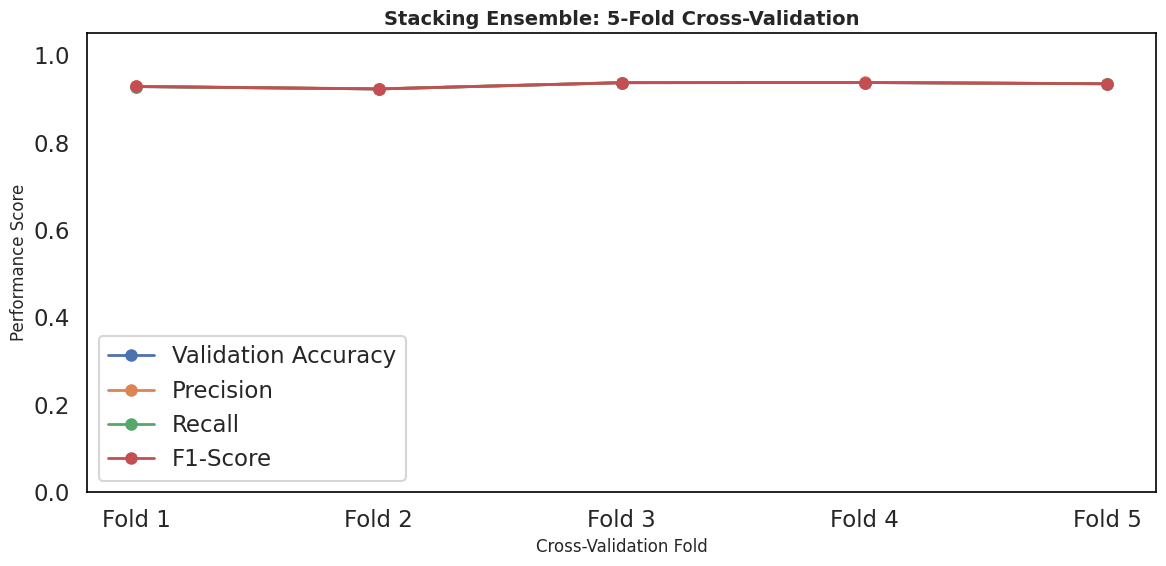


CROSS-VALIDATION SUMMARY (MEAN ± SD)

             Metric   Mean  Standard Deviation
Validation Accuracy 0.9320              0.0064
          Precision 0.9323              0.0063
             Recall 0.9320              0.0064
           F1-Score 0.9320              0.0063


In [121]:
# ============================================================
# STACKING ENSEMBLE: 5-FOLD CROSS-VALIDATION VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),
    "Recall": make_scorer(
        recall_score,
        average="macro",
        zero_division=0
    ),
    "F1-Score": make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    )
}

# ------------------------------------------------------------
# 2. RUN CROSS-VALIDATION
# ------------------------------------------------------------

cv_results = cross_validate(
    stack_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1
)

# ------------------------------------------------------------
# 3. CREATE FOLD-WISE DATAFRAME
# ------------------------------------------------------------

cv_fold_results = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "Validation Accuracy": cv_results["test_Accuracy"],
    "Precision": cv_results["test_Precision"],
    "Recall": cv_results["test_Recall"],
    "F1-Score": cv_results["test_F1-Score"]
})

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS\n")
print(cv_fold_results.round(4).to_string(index=False))

# ------------------------------------------------------------
# 4. VISUALIZE FOLD-WISE PERFORMANCE
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

metrics = [
    "Validation Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

for metric in metrics:
    plt.plot(
        cv_fold_results["Fold"],
        cv_fold_results[metric],
        marker="o",
        linewidth=2,
        markersize=8,
        label=metric
    )

plt.title(
    "Stacking Ensemble: 5-Fold Cross-Validation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Cross-Validation Fold", fontsize=12)
plt.ylabel("Performance Score", fontsize=12)

plt.ylim(0, 1.05)
plt.legend(loc="best", frameon=True)
plt.grid(False)

# Complete rectangular boundary
ax = plt.gca()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. MEAN AND STANDARD DEVIATION
# ------------------------------------------------------------

cv_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [
        cv_fold_results[m].mean() for m in metrics
    ],
    "Standard Deviation": [
        cv_fold_results[m].std() for m in metrics
    ]
})

print("\nCROSS-VALIDATION SUMMARY (MEAN ± SD)\n")
print(cv_summary.round(4).to_string(index=False))

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

et_pipeline_tuning = Pipeline([
    ("preprocessor", preprocessor_et),

    ("classifier", ExtraTreesClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [200, 300, 500, 700],

    "classifier__max_depth": [8, 10, 12, 15, 20, None],

    "classifier__min_samples_split": [5, 10, 15, 20],

    "classifier__min_samples_leaf": [2, 4, 6, 8, 10],

    "classifier__max_features": ["sqrt", "log2", 0.5],

    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search_et = RandomizedSearchCV(
    estimator=et_pipeline_tuning,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Optimize using the balanced training dataset
random_search_et.fit(X_train_balanced, y_balanced)

best_extra_trees = random_search_et.best_estimator_

print("Best Parameters:")
print(random_search_et.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search_et.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [ ]:
y_pred_et_optimized = best_extra_trees.predict(X_test)

print("\nOPTIMIZED EXTRA TREES PERFORMANCE")

print("Accuracy:",
      accuracy_score(y_test, y_pred_et_optimized))

print("Precision:",
      precision_score(y_test, y_pred_et_optimized,
                      average="weighted", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_et_optimized,
                   average="weighted", zero_division=0))

print("Weighted F1:",
      f1_score(y_test, y_pred_et_optimized,
               average="weighted", zero_division=0))

print("Macro F1:",
      f1_score(y_test, y_pred_et_optimized,
               average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_et_optimized,
    target_names=[str(c) for c in label_encoder.classes_],
    digits=4,
    zero_division=0
))


OPTIMIZED EXTRA TREES PERFORMANCE
Accuracy: 0.5678006708193579
Precision: 0.5886473738451038
Recall: 0.5678006708193579
Weighted F1: 0.5687240775710444
Macro F1: 0.5400735478169664

Classification Report:
              precision    recall  f1-score   support

      higher     0.3978    0.6143    0.4829       643
no education     0.7124    0.7423    0.7271      2119
     primary     0.6215    0.4366    0.5129      2373
   secondary     0.3955    0.4893    0.4375      1126

    accuracy                         0.5678      6261
   macro avg     0.5318    0.5706    0.5401      6261
weighted avg     0.5886    0.5678    0.5687      6261



## Cell 13 — Multiclass ROC-AUC (if supported)
ROC-AUC requires probability estimates and may fail if the test set lacks a class or the installed library cannot handle the label format. The exception is handled below.

In [ ]:
try:
    y_proba = hybrid_ai.predict_proba(X_test)
    model_classes = hybrid_ai.named_steps["hybrid_stacking"].classes_
    auc = roc_auc_score(
        y_test,
        y_proba,
        labels=model_classes,
        multi_class="ovr",
        average="macro"
    )
    print(f"Macro one-vs-rest ROC-AUC: {auc:.4f} ({auc*100:.2f}%)")
except Exception as e:
    print("ROC-AUC could not be calculated for this split:", repr(e))
    print("Check that every target class is present in the test set and that predicted probabilities are available.")


Macro one-vs-rest ROC-AUC: 0.8002 (80.02%)


## Cell 14 — Cross-validation on the training set
This gives a training-only cross-validation estimate. It is separate from the final held-out test metrics.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = cross_val_score(
    hybrid_ai,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("5-fold training CV macro-F1 scores:", np.round(cv_scores, 4))
print(f"Mean CV macro-F1: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


5-fold training CV macro-F1 scores: [0.532  0.5256 0.5184 0.4962 0.5196]
Mean CV macro-F1: 0.5184 ± 0.0121


## Cell 15 — Permutation importance
Permutation importance estimates how much test-set macro-F1 drops when each original input column is shuffled. It can be computationally expensive; set `n_repeats=3` for a quicker first run.

,Feature,Importance_mean,Importance_std
0,Age,0.162954,0.005731
5,Wealth index,0.142152,0.005764
1,Region,0.066637,0.008152
6,Marital status,0.051122,0.006016
3,Religion,0.045387,0.001232
7,employment Status,0.029950,0.003008
4,Sex,0.022092,0.000719
2,Place of residence,0.021185,0.003717


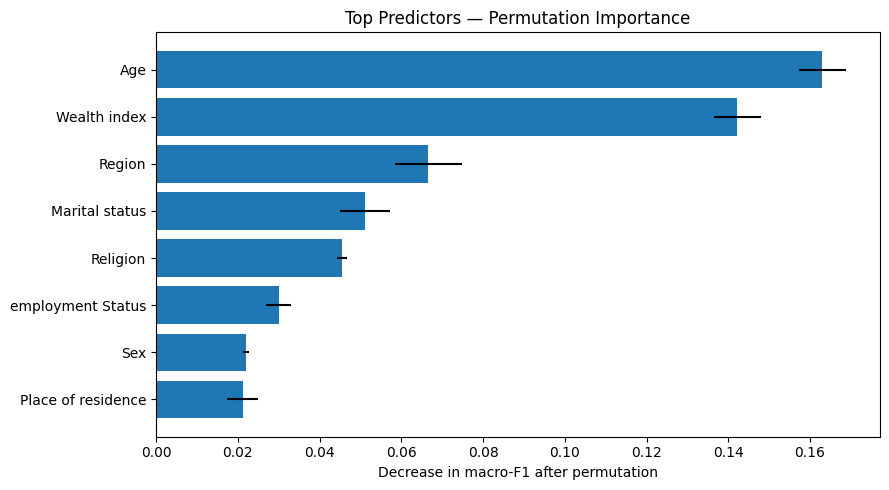

In [ ]:
perm = permutation_importance(
    hybrid_ai,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_mean": perm.importances_mean,
    "Importance_std": perm.importances_std
}).sort_values("Importance_mean", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
plot_df = importance_df.head(15).sort_values("Importance_mean")
plt.barh(plot_df["Feature"], plot_df["Importance_mean"], xerr=plot_df["Importance_std"])
plt.xlabel("Decrease in macro-F1 after permutation")
plt.title("Top Predictors — Permutation Importance")
plt.tight_layout()
plt.show()


## Cell 16 — Save the trained model and metadata
The saved pipeline includes preprocessing and the hybrid model. Keep the class labels and the dataset version with your experiment records.

In [ ]:
OUTPUT_DIR = Path("hybrid_ai_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

model_path = OUTPUT_DIR / "hybrid_ai_education_status.joblib"
joblib.dump(hybrid_ai, model_path)

metrics_path = OUTPUT_DIR / "test_metrics.csv"
pd.DataFrame([results]).to_csv(metrics_path, index=False)

importance_path = OUTPUT_DIR / "permutation_importance.csv"
importance_df.to_csv(importance_path, index=False)

print("Saved model:", model_path.resolve())
print("Saved metrics:", metrics_path.resolve())
print("Saved feature importance:", importance_path.resolve())


Saved model: /content/hybrid_ai_outputs/hybrid_ai_education_status.joblib
Saved metrics: /content/hybrid_ai_outputs/test_metrics.csv
Saved feature importance: /content/hybrid_ai_outputs/permutation_importance.csv


## Cell 17 — Predict for new records
Provide every predictor column used during training, with the same column names. The example uses an existing test row purely to demonstrate the prediction workflow; replace it with a genuinely new record for real use.

In [ ]:
# Demonstration only: predict one record from the held-out test set
sample_record = X_test.iloc[[0]].copy()
predicted_class = hybrid_ai.predict(sample_record)[0]

print("Input record:")
display(sample_record)
print("Predicted Education Status:", predicted_class)

if hasattr(hybrid_ai, "predict_proba"):
    probabilities = hybrid_ai.predict_proba(sample_record)[0]
    classes = hybrid_ai.named_steps["hybrid_stacking"].classes_
    probability_table = pd.DataFrame({
        "Education Status": classes,
        "Predicted probability": probabilities
    }).sort_values("Predicted probability", ascending=False)
    display(probability_table)


Input record:


,Age,Region,Place of residence,Religion,Sex,Wealth index,Marital status,employment Status
13742,39,amhara,urban,orthodox,male,middle,married,yes


Predicted Education Status: no education


,Education Status,Predicted probability
1,no education,0.838780
2,primary,0.091475
3,secondary,0.036097
0,higher,0.033648


## Research and reporting notes

- Do not report model performance until you run the notebook and verify the outputs.
- Use the held-out test set only for final evaluation; do not repeatedly tune models against it.
- If rows represent a complex survey, household members, or clustered samples, account for the survey design and possible dependence between records. If the data are from DHS, check whether survey weights, strata, and clusters are available.
- Check for possible label leakage and whether the target categories are consistently defined.
- High predictive performance does not prove that a feature causes educational attainment.
- For a publication, compare the hybrid model with individual baselines using the same split and report class-wise metrics, confidence intervals where feasible, and limitations.